In [9]:
from pathlib import Path
import sys
import random
import json
import shutil
import time

import numpy as np
import pandas as pd
import torch
import torchvision
import timm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DATA_ROOT = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-10k-preprocessed-face-images"
)

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
MODELS_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [MODELS_DIR, CHECKPOINT_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

(MODELS_DIR / "__init__.py").touch()

assert DATA_ROOT.exists(), f"Dataset not found: {DATA_ROOT}"
assert (DATA_ROOT / "dfdc_10k_metadata.csv").exists()

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Timm:", timm.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_ROOT)
print("Project:", PROJECT_DIR)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Timm: 1.0.30
Device: cuda:0
GPU: Tesla T4
Dataset: /kaggle/input/datasets/haiderrasoolqadri/dfdc-10k-preprocessed-face-images
Project: /kaggle/working/dfdc_reproduction


In [10]:
from sklearn.model_selection import GroupShuffleSplit

metadata = pd.read_csv(DATA_ROOT / "dfdc_10k_metadata.csv")

metadata["relative_path"] = metadata["image_path"].apply(
    lambda p: str(Path("DFDC_10K_Faces") / Path(p).parent.name / Path(p).name)
)

metadata["source_id"] = metadata["original"].fillna(metadata["video"])
metadata["label_id"] = metadata["label"].map({"REAL": 0, "FAKE": 1})

assert metadata["label_id"].notna().all()
assert metadata["relative_path"].map(
    lambda p: (DATA_ROOT / p).is_file()
).all(), "Some image files are missing"

splitter = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=SEED
)

train_idx, temp_idx = next(
    splitter.split(metadata, groups=metadata["source_id"])
)

train_df = metadata.iloc[train_idx].copy()
temp_df = metadata.iloc[temp_idx].copy()

splitter2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=SEED
)

valid_idx, test_idx = next(
    splitter2.split(temp_df, groups=temp_df["source_id"])
)

valid_df = temp_df.iloc[valid_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

train_df["split"] = "train"
valid_df["split"] = "valid"
test_df["split"] = "test"

manifest = pd.concat(
    [train_df, valid_df, test_df],
    ignore_index=True
)

groups = {
    split: set(part["source_id"])
    for split, part in manifest.groupby("split")
}

assert groups["train"].isdisjoint(groups["valid"])
assert groups["train"].isdisjoint(groups["test"])
assert groups["valid"].isdisjoint(groups["test"])

MANIFEST_PATH = PROJECT_DIR / "dfdc_split_manifest.csv"

manifest[
    [
        "relative_path", "video", "frame_idx",
        "label", "label_id", "confidence",
        "original", "source_id", "split"
    ]
].to_csv(MANIFEST_PATH, index=False)

print(pd.crosstab(manifest["split"], manifest["label"], margins=True))
print("\nSplit percentages:")
print((manifest["split"].value_counts(normalize=True) * 100).round(2))
print("\nManifest:", MANIFEST_PATH)

label  FAKE  REAL   All
split                  
test   1048   550  1598
train  3705  2749  6454
valid  1038   500  1538
All    5791  3799  9590

Split percentages:
split
train    67.30
test     16.66
valid    16.04
Name: proportion, dtype: float64

Manifest: /kaggle/working/dfdc_reproduction/dfdc_split_manifest.csv


In [11]:
config_code = '''
from pathlib import Path

DATA_ROOT = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-10k-preprocessed-face-images"
)

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
MANIFEST_PATH = PROJECT_DIR / "dfdc_split_manifest.csv"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

SEED = 42
IMAGE_SIZE = 299
CLASS_TO_IDX = {"REAL": 0, "FAKE": 1}
NUM_WORKERS = 2

MODEL_CONFIGS = {
    "xception": {
        "batch_size": 32,
        "learning_rate": 1e-4,
        "weight_decay": 0.0,
        "full_epochs": 30,
        "patience": 5,
    },
    "vgg16": {
        "batch_size": 8,
        "learning_rate": 1e-4,
        "weight_decay": 0.0,
        "full_epochs": 20,
        "patience": 5,
    },
    "resnet50": {
        "batch_size": 16,
        "learning_rate": 5e-5,
        "weight_decay": 1e-5,
        "full_epochs": 25,
        "patience": 5,
    },
    "resnet101": {
        "batch_size": 16,
        "learning_rate": 5e-5,
        "weight_decay": 1e-5,
        "full_epochs": 25,
        "patience": 5,
    },
}
'''

(PROJECT_DIR / "config.py").write_text(config_code.strip() + "\n")

dataset_code = '''
import random
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from config import (
    DATA_ROOT, MANIFEST_PATH, IMAGE_SIZE,
    CLASS_TO_IDX, NUM_WORKERS, SEED
)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=15, scale=(0.8, 1.2)),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])


class DFDCDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]
        image_path = DATA_ROOT / row["relative_path"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = CLASS_TO_IDX[row["label"]]

        return image, torch.tensor(label, dtype=torch.long)


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def get_dataloaders(batch_size):
    df = pd.read_csv(MANIFEST_PATH)

    loaders = {}

    for split in ["train", "valid", "test"]:
        dataset = DFDCDataset(
            df[df["split"] == split],
            train_transform if split == "train" else eval_transform
        )

        generator = torch.Generator().manual_seed(SEED)

        loaders[split] = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=(split == "train"),
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),
            worker_init_fn=seed_worker,
            generator=generator
        )

    return loaders
'''

(PROJECT_DIR / "dataset.py").write_text(dataset_code.strip() + "\n")

print("Created:", PROJECT_DIR / "config.py")
print("Created:", PROJECT_DIR / "dataset.py")

Created: /kaggle/working/dfdc_reproduction/config.py
Created: /kaggle/working/dfdc_reproduction/dataset.py


In [12]:
xception_code = '''
import torch
import torch.nn as nn
import timm


class XceptionDetector(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        self.backbone = timm.create_model(
            "xception",
            pretrained=pretrained,
            num_classes=0,
            global_pool="avg"
        )

        for p in self.backbone.parameters():
            p.requires_grad = False

        for name, p in self.backbone.named_parameters():
            if name.startswith((
                "block12", "conv3", "bn3", "conv4", "bn4"
            )):
                p.requires_grad = True

        self.classifier = nn.Sequential(
            nn.Linear(self.backbone.num_features, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 2)
        )

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.classifier(self.backbone(x))
'''

vgg16_code = '''
import torch
import torch.nn as nn
from torchvision.models import vgg16, VGG16_Weights


class VGG16Detector(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        base = vgg16(
            weights=VGG16_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        self.backbone = base.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        for p in self.backbone.parameters():
            p.requires_grad = False

        for p in self.backbone[24:].parameters():
            p.requires_grad = True

        self.classifier = nn.Sequential(
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, 2)
        )

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.backbone(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)
'''

resnet50_code = '''
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights


class ResNet50Detector(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        self.backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V2
            if pretrained else None
        )

        features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        for p in self.backbone.parameters():
            p.requires_grad = False

        for p in self.backbone.layer4.parameters():
            p.requires_grad = True

        self.classifier = nn.Sequential(
            nn.Linear(features, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 2)
        )

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.classifier(self.backbone(x))
'''

resnet101_code = '''
import torch
import torch.nn as nn
from torchvision.models import resnet101, ResNet101_Weights


class ResNet101Detector(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        self.backbone = resnet101(
            weights=ResNet101_Weights.IMAGENET1K_V2
            if pretrained else None
        )

        features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        for p in self.backbone.parameters():
            p.requires_grad = False

        for p in self.backbone.layer4.parameters():
            p.requires_grad = True

        self.classifier = nn.Sequential(
            nn.Linear(features, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 2)
        )

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.classifier(self.backbone(x))
'''

model_sources = {
    "xception.py": xception_code,
    "vgg16.py": vgg16_code,
    "resnet50.py": resnet50_code,
    "resnet101.py": resnet101_code,
}

for filename, source in model_sources.items():
    path = MODELS_DIR / filename
    path.write_text(source.strip() + "\n")
    print("Created:", path)

Created: /kaggle/working/dfdc_reproduction/models/xception.py
Created: /kaggle/working/dfdc_reproduction/models/vgg16.py
Created: /kaggle/working/dfdc_reproduction/models/resnet50.py
Created: /kaggle/working/dfdc_reproduction/models/resnet101.py


In [13]:
trainer_code = '''
import json
import random
import time

import numpy as np
import torch
import torch.nn as nn

from torch.amp import autocast, GradScaler
from tqdm.auto import tqdm

from config import MODEL_CONFIGS, CHECKPOINT_DIR, RESULTS_DIR
from dataset import get_dataloaders

from models.xception import XceptionDetector
from models.vgg16 import VGG16Detector
from models.resnet50 import ResNet50Detector
from models.resnet101 import ResNet101Detector


MODEL_CLASSES = {
    "xception": XceptionDetector,
    "vgg16": VGG16Detector,
    "resnet50": ResNet50Detector,
    "resnet101": ResNet101Detector
}


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def create_model(name, pretrained=True):
    return MODEL_CLASSES[name](pretrained=pretrained)


def run_epoch(model, loader, criterion, optimizer, scaler, device, training):
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation"
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with autocast(
                device_type="cuda",
                enabled=(device.type == "cuda")
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_size = labels.size(0)
        total_samples += batch_size
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(1) == labels).sum().item()

        progress.set_postfix(
            loss=f"{total_loss / total_samples:.4f}",
            accuracy=f"{total_correct / total_samples:.4f}"
        )

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples
    }


def train_model(name, epochs=1, resume=False):
    set_seed()

    config = MODEL_CONFIGS[name]
    device = torch.device(
        "cuda:0" if torch.cuda.is_available() else "cpu"
    )

    loaders = get_dataloaders(config["batch_size"])
    model = create_model(name, pretrained=not resume).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"]
    )

    scaler = GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    scheduler = None

    if name == "xception":
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer,
            step_size=10,
            gamma=0.5
        )

    checkpoint_path = CHECKPOINT_DIR / f"{name}_latest.pth"
    best_path = CHECKPOINT_DIR / f"{name}_best.pth"
    history_path = RESULTS_DIR / f"{name}_history.json"

    start_epoch = 1
    best_loss = float("inf")
    patience_counter = 0
    history = []

    if resume:
        if not checkpoint_path.exists():
            raise FileNotFoundError(checkpoint_path)

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

        if scheduler and checkpoint.get("scheduler_state_dict"):
            scheduler.load_state_dict(
                checkpoint["scheduler_state_dict"]
            )

        start_epoch = checkpoint["epoch"] + 1
        best_loss = checkpoint["best_val_loss"]
        patience_counter = checkpoint.get("patience_counter", 0)
        history = checkpoint.get("history", [])

    for epoch in range(start_epoch, epochs + 1):
        started = time.time()

        print(f"\\n{name.upper()} | Epoch {epoch}/{epochs}")

        train_metrics = run_epoch(
            model, loaders["train"], criterion,
            optimizer, scaler, device, True
        )

        valid_metrics = run_epoch(
            model, loaders["valid"], criterion,
            None, scaler, device, False
        )

        if scheduler:
            scheduler.step()

        record = {
            "model": name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": valid_metrics["loss"],
            "val_accuracy": valid_metrics["accuracy"],
            "minutes": (time.time() - started) / 60
        }

        history.append(record)

        improved = valid_metrics["loss"] < best_loss

        if improved:
            best_loss = valid_metrics["loss"]
            patience_counter = 0
        else:
            patience_counter += 1

        state = {
            "model_name": name,
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "scheduler_state_dict": (
                scheduler.state_dict() if scheduler else None
            ),
            "best_val_loss": best_loss,
            "patience_counter": patience_counter,
            "history": history
        }

        torch.save(state, checkpoint_path)

        if improved:
            torch.save(state, best_path)

        history_path.write_text(
            json.dumps(history, indent=2)
        )

        print(
            f"Train: loss={train_metrics['loss']:.4f}, "
            f"acc={train_metrics['accuracy']:.4%}"
        )
        print(
            f"Valid: loss={valid_metrics['loss']:.4f}, "
            f"acc={valid_metrics['accuracy']:.4%}"
        )
        print(f"Time: {record['minutes']:.2f} min")

        if patience_counter >= config["patience"]:
            print("Early stopping triggered")
            break

    del model, optimizer, scaler

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return history
'''

(PROJECT_DIR / "trainer.py").write_text(
    trainer_code.strip() + "\n"
)

print("Created:", PROJECT_DIR / "trainer.py")

Created: /kaggle/working/dfdc_reproduction/trainer.py


In [14]:
evaluate_code = '''
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from torch.amp import autocast

from config import CHECKPOINT_DIR
from trainer import create_model


def load_trained_model(name, device):
    model = create_model(name, pretrained=False)

    checkpoint = torch.load(
        CHECKPOINT_DIR / f"{name}_best.pth",
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    return model


@torch.inference_mode()
def predict_probabilities(model, loader, device):
    all_labels = []
    all_probs = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)

        with autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            logits = model(images)

        probabilities = torch.softmax(
            logits.float(), dim=1
        )[:, 1]

        all_probs.extend(probabilities.cpu().numpy())
        all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_probs)


def calculate_metrics(labels, probabilities):
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "precision": float(precision_score(
            labels, predictions, zero_division=0
        )),
        "recall": float(recall_score(
            labels, predictions, zero_division=0
        )),
        "f1": float(f1_score(
            labels, predictions, zero_division=0
        )),
        "roc_auc": float(roc_auc_score(
            labels, probabilities
        )),
        "confusion_matrix": confusion_matrix(
            labels, predictions, labels=[0, 1]
        ).tolist()
    }
'''

ensemble_code = '''
import numpy as np


def average_ensemble(resnet50_probs, resnet101_probs):
    if len(resnet50_probs) != len(resnet101_probs):
        raise ValueError("Prediction lengths do not match")

    return (
        np.asarray(resnet50_probs) +
        np.asarray(resnet101_probs)
    ) / 2.0
'''

(PROJECT_DIR / "evaluate.py").write_text(
    evaluate_code.strip() + "\n"
)

(PROJECT_DIR / "ensemble.py").write_text(
    ensemble_code.strip() + "\n"
)

print("Created:", PROJECT_DIR / "evaluate.py")
print("Created:", PROJECT_DIR / "ensemble.py")

Created: /kaggle/working/dfdc_reproduction/evaluate.py
Created: /kaggle/working/dfdc_reproduction/ensemble.py


In [15]:
from trainer import train_model

xception_history = train_model(
    name="xception",
    epochs=1,
    resume=False
)

/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(



XCEPTION | Epoch 1/1


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/49 [00:00<?, ?it/s]

Train: loss=0.4073, acc=80.5392%
Valid: loss=0.4557, acc=83.0949%
Time: 0.58 min


In [16]:
vgg16_history = train_model(
    name="vgg16",
    epochs=1,
    resume=False
)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 218MB/s]  



VGG16 | Epoch 1/1


Training:   0%|          | 0/807 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4dff3a6340>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4dff3a6340>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/193 [00:00<?, ?it/s]

Train: loss=0.4143, acc=78.2615%
Valid: loss=0.5107, acc=83.2250%
Time: 0.74 min


In [19]:
resnet50_history = train_model(
    name="resnet50",
    epochs=1,
    resume=False
)
resnet101_history = train_model(
    name="resnet101",
    epochs=1,
    resume=False
)


RESNET50 | Epoch 1/1


Training:   0%|          | 0/404 [00:00<?, ?it/s]

Validation:   0%|          | 0/97 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4dff3a6340>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Train: loss=0.4401, acc=77.4403%
Valid: loss=0.3302, acc=85.8257%
Time: 0.53 min
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 223MB/s] 



RESNET101 | Epoch 1/1


Training:   0%|          | 0/404 [00:00<?, ?it/s]

Validation:   0%|          | 0/97 [00:00<?, ?it/s]

Train: loss=0.4445, acc=76.8361%
Valid: loss=0.3979, acc=81.4044%
Time: 0.76 min


In [20]:
import gc
import pandas as pd
import torch

from dataset import get_dataloaders
from evaluate import (
    load_trained_model,
    predict_probabilities,
    calculate_metrics
)
from ensemble import average_ensemble

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model_names = [
    "xception",
    "vgg16",
    "resnet50",
    "resnet101"
]

results = []
predictions = {}
reference_labels = None

for name in model_names:
    print(f"\nEvaluating {name}")

    model = load_trained_model(name, device)

    # Same test ordering for all models
    _, _, test_loader = (
        lambda d: (d["train"], d["valid"], d["test"])
    )(get_dataloaders(batch_size=16))

    labels, probs = predict_probabilities(
        model, test_loader, device
    )

    if reference_labels is None:
        reference_labels = labels
    else:
        assert (reference_labels == labels).all()

    predictions[name] = probs

    metrics = calculate_metrics(labels, probs)

    results.append({
        "model": name,
        **{k: v for k, v in metrics.items()
           if k != "confusion_matrix"}
    })

    print(metrics)

    del model, test_loader
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()


ensemble_probs = average_ensemble(
    predictions["resnet50"],
    predictions["resnet101"]
)

ensemble_metrics = calculate_metrics(
    reference_labels,
    ensemble_probs
)

results.append({
    "model": "resnet50_resnet101_ensemble",
    **{
        k: v for k, v in ensemble_metrics.items()
        if k != "confusion_matrix"
    }
})

comparison = pd.DataFrame(results)

comparison.to_csv(
    RESULTS_DIR / "model_comparison_1epoch.csv",
    index=False
)

print("\nModel comparison:")
print(comparison.to_string(index=False))

print("\nEnsemble confusion matrix:")
print(ensemble_metrics["confusion_matrix"])


Evaluating xception


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


{'accuracy': 0.7634543178973717, 'precision': 0.9731638418079096, 'recall': 0.6574427480916031, 'f1': 0.784738041002278, 'roc_auc': 0.913678001387925, 'confusion_matrix': [[531, 19], [359, 689]]}

Evaluating vgg16
{'accuracy': 0.8804755944931164, 'precision': 0.9777034559643255, 'recall': 0.8368320610687023, 'f1': 0.9017994858611825, 'roc_auc': 0.9520202984038861, 'confusion_matrix': [[530, 20], [171, 877]]}

Evaluating resnet50
{'accuracy': 0.8160200250312891, 'precision': 0.994750656167979, 'recall': 0.7232824427480916, 'f1': 0.8375690607734807, 'roc_auc': 0.9695098889659958, 'confusion_matrix': [[546, 4], [290, 758]]}

Evaluating resnet101
{'accuracy': 0.7065081351689612, 'precision': 1.0, 'recall': 0.5524809160305344, 'f1': 0.7117393976644131, 'roc_auc': 0.9625702637057598, 'confusion_matrix': [[550, 0], [469, 579]]}

Model comparison:
                      model  accuracy  precision   recall       f1  roc_auc
                   xception  0.763454   0.973164 0.657443 0.784738 0.913

In [21]:
ATTACKS_DIR = PROJECT_DIR / "attacks"
ATTACKS_DIR.mkdir(parents=True, exist_ok=True)
(ATTACKS_DIR / "__init__.py").touch()

fgsm_code = '''
import torch
import torch.nn as nn


def fgsm_attack(model, images, labels, epsilon=0.01):
    """
    Untargeted FGSM attack.

    images: tensors in [0, 1]
    labels: ground-truth labels
    epsilon: maximum pixel perturbation
    """
    if not 0 <= epsilon <= 1:
        raise ValueError("epsilon must be between 0 and 1")

    model.eval()

    x = images.detach().clone().requires_grad_(True)

    with torch.enable_grad():
        with torch.autocast(
            device_type="cuda",
            enabled=False
        ):
            logits = model(x)
            loss = nn.functional.cross_entropy(logits, labels)

        gradient = torch.autograd.grad(
            loss, x, only_inputs=True
        )[0]

    adversarial = x + epsilon * gradient.sign()
    adversarial = adversarial.clamp(0.0, 1.0)

    return adversarial.detach()
'''

(ATTACKS_DIR / "fgsm.py").write_text(fgsm_code.strip() + "\n")

print("Created:", ATTACKS_DIR / "fgsm.py")

Created: /kaggle/working/dfdc_reproduction/attacks/fgsm.py


In [22]:
import gc
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from dataset import DFDCDataset, eval_transform
from evaluate import load_trained_model, calculate_metrics
from attacks.fgsm import fgsm_attack

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
EPSILON = 0.01

test_df = pd.read_csv(MANIFEST_PATH)
test_df = test_df[test_df["split"] == "test"]

test_dataset = DFDCDataset(test_df, eval_transform)

attack_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

model_names = ["xception", "vgg16", "resnet50", "resnet101"]
attack_results = []
clean_probs = {}
adv_probs = {}
reference_labels = None

for name in model_names:
    print(f"\nFGSM evaluation: {name}")

    model = load_trained_model(name, device)
    model.eval()

    labels_all = []
    clean_all = []
    adv_all = []

    for images, labels in tqdm(attack_loader, desc=name):
        images = images.to(device)
        labels = labels.to(device)

        with torch.no_grad():
            clean_logits = model(images)
            clean_p = torch.softmax(clean_logits.float(), dim=1)[:, 1]

        adv_images = fgsm_attack(
            model, images, labels, epsilon=EPSILON
        )

        with torch.no_grad():
            adv_logits = model(adv_images)
            adv_p = torch.softmax(adv_logits.float(), dim=1)[:, 1]

        labels_all.extend(labels.cpu().numpy())
        clean_all.extend(clean_p.cpu().numpy())
        adv_all.extend(adv_p.cpu().numpy())

    labels_all = np.asarray(labels_all)
    clean_all = np.asarray(clean_all)
    adv_all = np.asarray(adv_all)

    if reference_labels is None:
        reference_labels = labels_all
    else:
        assert np.array_equal(reference_labels, labels_all)

    clean_probs[name] = clean_all
    adv_probs[name] = adv_all

    clean_metrics = calculate_metrics(labels_all, clean_all)
    adv_metrics = calculate_metrics(labels_all, adv_all)

    attack_results.append({
        "model": name,
        "attack": "FGSM",
        "epsilon": EPSILON,
        "clean_accuracy": clean_metrics["accuracy"],
        "adversarial_accuracy": adv_metrics["accuracy"],
        "accuracy_drop": (
            clean_metrics["accuracy"] - adv_metrics["accuracy"]
        ),
        "clean_f1": clean_metrics["f1"],
        "adversarial_f1": adv_metrics["f1"],
        "clean_auc": clean_metrics["roc_auc"],
        "adversarial_auc": adv_metrics["roc_auc"]
    })

    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


# Ensemble: evaluate attacks crafted against each ResNet separately
ensemble_clean = (
    clean_probs["resnet50"] + clean_probs["resnet101"]
) / 2.0

for attack_source in ["resnet50", "resnet101"]:
    source_adv = adv_probs[attack_source]

    # Load the other ResNet to evaluate the SAME attacked images.
    other_name = (
        "resnet101" if attack_source == "resnet50"
        else "resnet50"
    )

    source_model = load_trained_model(attack_source, device)
    other_model = load_trained_model(other_name, device)

    ensemble_adv_all = []

    for images, labels in tqdm(
        attack_loader, desc=f"Ensemble attack via {attack_source}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        adv_images = fgsm_attack(
            source_model, images, labels, epsilon=EPSILON
        )

        with torch.no_grad():
            p1 = torch.softmax(
                source_model(adv_images).float(), dim=1
            )[:, 1]
            p2 = torch.softmax(
                other_model(adv_images).float(), dim=1
            )[:, 1]

        ensemble_adv_all.extend(
            ((p1 + p2) / 2).cpu().numpy()
        )

    ensemble_adv_all = np.asarray(ensemble_adv_all)

    clean_metrics = calculate_metrics(
        reference_labels, ensemble_clean
    )
    adv_metrics = calculate_metrics(
        reference_labels, ensemble_adv_all
    )

    attack_results.append({
        "model": "resnet50_resnet101_ensemble",
        "attack": f"FGSM via {attack_source}",
        "epsilon": EPSILON,
        "clean_accuracy": clean_metrics["accuracy"],
        "adversarial_accuracy": adv_metrics["accuracy"],
        "accuracy_drop": (
            clean_metrics["accuracy"] - adv_metrics["accuracy"]
        ),
        "clean_f1": clean_metrics["f1"],
        "adversarial_f1": adv_metrics["f1"],
        "clean_auc": clean_metrics["roc_auc"],
        "adversarial_auc": adv_metrics["roc_auc"]
    })

    del source_model, other_model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


attack_comparison = pd.DataFrame(attack_results)

attack_comparison.to_csv(
    RESULTS_DIR / "fgsm_robustness_1epoch.csv",
    index=False
)

print("\nFGSM robustness comparison:")
print(attack_comparison.to_string(index=False))


FGSM evaluation: xception


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


xception:   0%|          | 0/200 [00:00<?, ?it/s]


FGSM evaluation: vgg16


vgg16:   0%|          | 0/200 [00:00<?, ?it/s]


FGSM evaluation: resnet50


... (2 outputs left out)

resnet101:   0%|          | 0/200 [00:00<?, ?it/s]

Ensemble attack via resnet50:   0%|          | 0/200 [00:00<?, ?it/s]

Ensemble attack via resnet101:   0%|          | 0/200 [00:00<?, ?it/s]


FGSM robustness comparison:
                      model             attack  epsilon  clean_accuracy  adversarial_accuracy  accuracy_drop  clean_f1  adversarial_f1  clean_auc  adversarial_auc
                   xception               FGSM     0.01        0.763454              0.164581       0.598874  0.784983        0.264463   0.913574         0.042918
                      vgg16               FGSM     0.01        0.880476              0.032541       0.847935  0.901799        0.063030   0.952004         0.000224
                   resnet50               FGSM     0.01        0.815394              0.633292       0.182103  0.837107        0.771272   0.969285         0.538206
                  resnet101               FGSM     0.01        0.706508              0.651439       0.055069  0.711739        0.765276   0.962061         0.625968
resnet50_resnet101_ensemble  FGSM via resnet50     0.01        0.780350              0.696496       0.083855  0.798854        0.805143   0.980715         0.

In [23]:
from pathlib import Path
import shutil

project = Path("/kaggle/working/dfdc_reproduction")

# Check that all four models have resumable checkpoints
for name in ["xception", "vgg16", "resnet50", "resnet101"]:
    checkpoint = project / "checkpoints" / f"{name}_latest.pth"
    assert checkpoint.exists(), f"Missing: {checkpoint}"

zip_path = shutil.make_archive(
    "/kaggle/working/dfdc_reproduction_backup",
    "zip",
    root_dir=project
)

print("Backup ready:", zip_path)
print("Size:", round(Path(zip_path).stat().st_size / 1024**2, 2), "MB")

Backup ready: /kaggle/working/dfdc_reproduction_backup.zip
Size: 1409.27 MB


In [24]:
from pathlib import Path

working = Path("/kaggle/working")

for path in sorted(working.iterdir()):
    if path.is_file():
        print(path.name, round(path.stat().st_size / 1024**2, 2), "MB")
    elif path.is_dir():
        print("[FOLDER]", path.name)

print("\nCheckpoints:")
for path in sorted(
    (working / "dfdc_reproduction" / "checkpoints").glob("*.pth")
):
    print(path.name, round(path.stat().st_size / 1024**2, 2), "MB")

[FOLDER] .virtual_documents
[FOLDER] dfdc_reproduction
dfdc_reproduction_backup.zip 1409.27 MB
dfdc_split_manifest.csv 2.65 MB
xception_epoch1.pth 143.5 MB

Checkpoints:
resnet101_best.pth 288.96 MB
resnet101_latest.pth 288.96 MB
resnet50_best.pth 216.2 MB
resnet50_latest.pth 216.21 MB
vgg16_best.pth 113.18 MB
vgg16_latest.pth 113.18 MB
xception_best.pth 143.5 MB
xception_latest.pth 143.5 MB


In [25]:
import os
import json
import shutil
import subprocess
from pathlib import Path

backup = Path("/kaggle/working/dfdc_reproduction_backup.zip")
upload_dir = Path("/kaggle/working/epoch1_dataset_upload")
upload_dir.mkdir(exist_ok=True)

assert backup.exists(), "Backup ZIP not found"

# Link the existing ZIP without making another 1.4 GB copy
target = upload_dir / backup.name
if not target.exists():
    os.link(backup, target)

metadata = {
    "title": "DFDC Deepfake Reproduction Epoch 1 Backup",
    "id": "haiderrasoolqadri/dfdc-deepfake-epoch1-backup",
    "licenses": [{"name": "CC0-1.0"}]
}

(upload_dir / "dataset-metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

print("Upload folder:", upload_dir)
print("Backup size (MB):", round(backup.stat().st_size / 1024**2, 2))
print("Files:", [p.name for p in upload_dir.iterdir()])

Upload folder: /kaggle/working/epoch1_dataset_upload
Backup size (MB): 1409.27
Files: ['dataset-metadata.json', 'dfdc_reproduction_backup.zip']


In [1]:
from pathlib import Path

print("GPU check:")
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nSearching for saved backup:")
backups = list(
    Path("/kaggle/input").rglob("dfdc_reproduction_backup.zip")
)

for backup in backups:
    print("Found:", backup)
    print("Size (MB):", round(backup.stat().st_size / 1024**2, 2))

print("\nOriginal dataset:")
dataset = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-10k-preprocessed-face-images"
)
print("Dataset path exists:", dataset.exists())

print("\nBackup found:", len(backups) > 0)

GPU check:
CUDA available: True
GPU: Tesla T4

Searching for saved backup:
Found: /kaggle/input/notebooks/haiderrasoolqadri/dfdc-deepfake-reproduction/dfdc_reproduction_backup.zip
Size (MB): 1409.27
Found: /kaggle/input/notebooks/haiderrasoolqadri/dfdc-deepfake-reproduction/epoch1_dataset_upload/dfdc_reproduction_backup.zip
Size (MB): 1409.27

Original dataset:
Dataset path exists: True

Backup found: True


In [2]:
from pathlib import Path
import zipfile
import sys

backup_path = backups[0]
project_dir = Path("/kaggle/working/dfdc_reproduction")

project_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(backup_path, "r") as z:
    z.extractall(project_dir)

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

print("Project restored successfully.")

for name in ["xception", "vgg16", "resnet50", "resnet101"]:
    path = project_dir / "checkpoints" / f"{name}_latest.pth"
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

Project restored successfully.
xception: FOUND
vgg16: FOUND
resnet50: FOUND
resnet101: FOUND


In [3]:
import torch

for name in ["xception", "vgg16", "resnet50", "resnet101"]:
    path = project_dir / "checkpoints" / f"{name}_latest.pth"

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print(
        f"{name}: saved epoch = {checkpoint.get('epoch', 'unknown')}"
    )

xception: saved epoch = 1
vgg16: saved epoch = 1
resnet50: saved epoch = 1
resnet101: saved epoch = 1


In [4]:
from trainer import train_model

train_model("xception", epochs=30, resume=True)
train_model("vgg16", epochs=20, resume=True)
train_model("resnet50", epochs=25, resume=True)
train_model("resnet101", epochs=25, resume=True)

/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(



XCEPTION | Epoch 2/30


Training:   0%|          | 0/202 [00:00<?, ?it/s]

Validation:   0%|          | 0/49 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>
Traceback (most recent call last):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>
    self._shutdown_workers()Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/util

Train: loss=0.1051, acc=96.0180%
Valid: loss=0.5557, acc=84.8505%
Time: 4.63 min

XCEPTION | Epoch 3/30


... (143 outputs left out)

Training:   0%|          | 0/404 [00:00<?, ?it/s]

Validation:   0%|          | 0/97 [00:00<?, ?it/s]

Train: loss=0.0632, acc=97.6449%
Valid: loss=0.1781, acc=93.6281%
Time: 0.79 min
Early stopping triggered


[{'model': 'resnet101',
  'epoch': 1,
  'train_loss': 0.44448543222910264,
  'train_accuracy': 0.7683607065385807,
  'val_loss': 0.3978841827191674,
  'val_accuracy': 0.8140442132639792,
  'minutes': 0.7934707522392273},
 {'model': 'resnet101',
  'epoch': 2,
  'train_loss': 0.07642482226205972,
  'train_accuracy': 0.9741245739076542,
  'val_loss': 0.2871273992430559,
  'val_accuracy': 0.8979193758127438,
  'minutes': 0.8081282138824463},
 {'model': 'resnet101',
  'epoch': 3,
  'train_loss': 0.20122190658378275,
  'train_accuracy': 0.9200495816547877,
  'val_loss': 0.19578542216391495,
  'val_accuracy': 0.9323797139141743,
  'minutes': 0.809929092725118},
 {'model': 'resnet101',
  'epoch': 4,
  'train_loss': 0.14261159453071195,
  'train_accuracy': 0.943910753021382,
  'val_loss': 0.2550863432946224,
  'val_accuracy': 0.9206762028608583,
  'minutes': 0.796526026725769},
 {'model': 'resnet101',
  'epoch': 5,
  'train_loss': 0.120324924315762,
  'train_accuracy': 0.9535171986365045,
  'va

In [6]:
import sys
import inspect
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import evaluate

print("Evaluation file:", evaluate.__file__)

print("\nAvailable functions:")
for name, obj in inspect.getmembers(evaluate, inspect.isfunction):
    if obj.__module__ == evaluate.__name__:
        print(f"{name}{inspect.signature(obj)}")

print("\nBest checkpoints:")
for name in ["xception", "vgg16", "resnet50", "resnet101"]:
    path = PROJECT_DIR / "checkpoints" / f"{name}_best.pth"
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

Evaluation file: /kaggle/working/dfdc_reproduction/evaluate.py

Available functions:
calculate_metrics(labels, probabilities)
load_trained_model(name, device)
predict_probabilities(model, loader, device)

Best checkpoints:
xception: FOUND
vgg16: FOUND
resnet50: FOUND
resnet101: FOUND


In [7]:
import inspect
import evaluate
import dataset

print("=== Evaluation Functions ===")
for name in [
    "load_trained_model",
    "predict_probabilities",
    "calculate_metrics"
]:
    fn = getattr(evaluate, name)
    print(f"{name}{inspect.signature(fn)}")

print("\n=== Dataset Functions ===")
for name, obj in inspect.getmembers(dataset, inspect.isfunction):
    if obj.__module__ == dataset.__name__:
        print(f"{name}{inspect.signature(obj)}")

print("\n=== ResNet101 Checkpoint ===")
from pathlib import Path

checkpoint = Path(
    "/kaggle/working/dfdc_reproduction/checkpoints/resnet101_best.pth"
)
print("ResNet101:", "FOUND" if checkpoint.exists() else "MISSING")

=== Evaluation Functions ===
load_trained_model(name, device)
predict_probabilities(model, loader, device)
calculate_metrics(labels, probabilities)

=== Dataset Functions ===
get_dataloaders(batch_size)
seed_worker(worker_id)

=== ResNet101 Checkpoint ===
ResNet101: FOUND


In [10]:
import sys
import gc
import torch
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
sys.path.insert(0, str(PROJECT_DIR))

from dataset import get_dataloaders
from evaluate import (
    load_trained_model,
    predict_probabilities,
    calculate_metrics
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Correct: get_dataloaders returns a dictionary
loaders = get_dataloaders(batch_size=16)
test_loader = loaders["test"]

print("Test images:", len(test_loader.dataset))
print("Test batches:", len(test_loader))

models = ["xception", "vgg16", "resnet50", "resnet101"]
results = []

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

for name in models:
    print(f"\n{'=' * 50}")
    print(f"Evaluating {name.upper()} on CLEAN TEST DATA")
    print(f"{'=' * 50}")

    # Load best checkpoint
    model = load_trained_model(name, device)
    model.eval()

    # Get predictions
    labels, probabilities = predict_probabilities(
        model, test_loader, device
    )

    # Calculate metrics
    metrics = calculate_metrics(labels, probabilities)

    results.append({
        "model": name,
        **metrics
    })

    print("Metrics:", metrics)

    # Save results after each model
    results_df = pd.DataFrame(results)
    results_df.to_csv(
        results_dir / "clean_test_results.csv",
        index=False
    )

    # Free GPU memory
    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\n========== FINAL CLEAN TEST RESULTS ==========")
display(results_df)

print(
    "\nResults saved to:",
    results_dir / "clean_test_results.csv"
)

Device: cuda
Test images: 1598
Test batches: 100

Evaluating XCEPTION on CLEAN TEST DATA


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Metrics: {'accuracy': 0.8648310387984981, 'precision': 0.9894117647058823, 'recall': 0.8024809160305344, 'f1': 0.8861959957850368, 'roc_auc': 0.9656575294934073, 'confusion_matrix': [[541, 9], [207, 841]]}

Evaluating VGG16 on CLEAN TEST DATA
Metrics: {'accuracy': 0.9230287859824781, 'precision': 0.9611166500498505, 'recall': 0.9198473282442748, 'f1': 0.9400292540224281, 'roc_auc': 0.9767123525329631, 'confusion_matrix': [[511, 39], [84, 964]]}

Evaluating RESNET50 on CLEAN TEST DATA
Metrics: {'accuracy': 0.8685857321652065, 'precision': 0.9952718676122931, 'recall': 0.8034351145038168, 'f1': 0.8891235480464625, 'roc_auc': 0.9789156835530882, 'confusion_matrix': [[546, 4], [206, 842]]}

Evaluating RESNET101 on CLEAN TEST DATA
Metrics: {'accuracy': 0.9130162703379224, 'precision': 0.9924160346695557, 'recall': 0.8740458015267175, 'f1': 0.9294774226281075, 'roc_auc': 0.9844873351839001, 'confusion_matrix': [[543, 7], [132, 916]]}

========== FINAL CLEAN TEST RESULTS ==========


,model,accuracy,precision,recall,f1,roc_auc,confusion_matrix
0,xception,0.864831,0.989412,0.802481,0.886196,0.965658,"[[541, 9], [207, 841]]"
1,vgg16,0.923029,0.961117,0.919847,0.940029,0.976712,"[[511, 39], [84, 964]]"
2,resnet50,0.868586,0.995272,0.803435,0.889124,0.978916,"[[546, 4], [206, 842]]"
3,resnet101,0.913016,0.992416,0.874046,0.929477,0.984487,"[[543, 7], [132, 916]]"



Results saved to: /kaggle/working/dfdc_reproduction/results/clean_test_results.csv


In [14]:
import sys
import gc
import torch
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
sys.path.insert(0, str(PROJECT_DIR))

from dataset import get_dataloaders
from evaluate import load_trained_model, calculate_metrics
from attacks.fgsm import fgsm_attack

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loaders = get_dataloaders(batch_size=16)
test_loader = loaders["test"]

# Verify pixel range before attacking
sample_images, sample_labels = next(iter(test_loader))

print("Image minimum:", sample_images.min().item())
print("Image maximum:", sample_images.max().item())

if sample_images.min() < 0 or sample_images.max() > 1:
    raise ValueError(
        "Images are not in [0,1]. FGSM needs adjustment "
        "for dataset normalization."
    )

# Attack strengths
epsilons = [0.0, 0.01, 0.03, 0.05]

model_names = ["xception", "vgg16", "resnet50", "resnet101"]

results = []

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

for name in model_names:

    print(f"\n{'='*55}")
    print(f"FGSM EVALUATION: {name.upper()}")
    print(f"{'='*55}")

    model = load_trained_model(name, device)
    model.eval()

    for epsilon in epsilons:

        all_labels = []
        all_probs = []

        for images, labels in tqdm(
            test_loader,
            desc=f"{name} eps={epsilon}"
        ):
            images = images.to(device)
            labels = labels.to(device)

            if epsilon == 0.0:
                adv_images = images
            else:
                adv_images = fgsm_attack(
                    model,
                    images,
                    labels,
                    epsilon=epsilon
                )

            with torch.inference_mode():
                logits = model(adv_images)
                probabilities = torch.softmax(
                    logits.float(), dim=1
                )[:, 1]

            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probabilities.cpu().numpy())

            metrics = calculate_metrics(
                np.asarray(all_labels),
                np.asarray(all_probs)
            )

        results.append({
            "model": name,
            "epsilon": epsilon,
            **metrics
        })

        print(
            f"Epsilon={epsilon:.2f} | "
            f"Accuracy={metrics['accuracy']:.4f} | "
            f"F1={metrics['f1']:.4f}"
        )

        # Save after every epsilon
        pd.DataFrame(results).to_csv(
            results_dir / "fgsm_test_results.csv",
            index=False
        )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

fgsm_df = pd.DataFrame(results)

print("\n========== FINAL FGSM RESULTS ==========")
display(
    fgsm_df[
        ["model", "epsilon", "accuracy", "precision",
         "recall", "f1", "roc_auc"]
    ]
)

print(
    "\nSaved to:",
    results_dir / "fgsm_test_results.csv"
)

Image minimum: 0.019607843831181526
Image maximum: 0.9333333373069763

FGSM EVALUATION: XCEPTION


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


xception eps=0.0:   0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Epsilon=0.00 | Accuracy=0.8655 | F1=0.8867


xception eps=0.01:   0%|          | 0/100 [00:00<?, ?it/s]

... (42 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>can only test a child process

Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>    self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/pyt

Epsilon=0.05 | Accuracy=0.6602 | F1=0.7941

========== FINAL FGSM RESULTS ==========


,model,epsilon,accuracy,precision,recall,f1,roc_auc
0,xception,0.00,0.865457,0.990577,0.802481,0.886663,0.965765
1,xception,0.01,0.446809,0.564976,0.680344,0.617316,0.110969
2,xception,0.03,0.664581,0.663474,0.991412,0.794950,0.459527
3,xception,0.05,0.655820,0.655820,1.000000,0.792139,0.526068
4,vgg16,0.00,0.923655,0.961155,0.920802,0.940546,0.976709
5,vgg16,0.01,0.080726,0.187221,0.120229,0.146426,0.002049
6,vgg16,0.03,0.590113,0.631614,0.899809,0.742227,0.107955
7,vgg16,0.05,0.650814,0.654088,0.992366,0.788476,0.226481
8,resnet50,0.00,0.867960,0.995266,0.802481,0.888537,0.978912
9,resnet50,0.01,0.645181,0.652698,0.980916,0.783835,0.595034



Saved to: /kaggle/working/dfdc_reproduction/results/fgsm_test_results.csv


In [15]:
import pandas as pd
import ast

path = "/kaggle/working/dfdc_reproduction/results/fgsm_test_results.csv"
df = pd.read_csv(path)

rows = []

for _, row in df.iterrows():
    cm = row["confusion_matrix"]

    if isinstance(cm, str):
        cm = ast.literal_eval(cm)

    tn, fp = cm[0]
    fn, tp = cm[1]

    rows.append({
        "model": row["model"],
        "epsilon": row["epsilon"],
        "accuracy": round(row["accuracy"] * 100, 2),
        "predicted_real": tn + fn,
        "predicted_fake": fp + tp,
        "real_recall_specificity": round(
            tn / (tn + fp) * 100, 2
        ),
        "fake_recall": round(
            tp / (tp + fn) * 100, 2
        )
    })

diagnostics = pd.DataFrame(rows)
display(diagnostics)

,model,epsilon,accuracy,predicted_real,predicted_fake,real_recall_specificity,fake_recall
0,xception,0.00,86.55,749,849,98.55,80.25
1,xception,0.01,44.68,336,1262,0.18,68.03
2,xception,0.03,66.46,32,1566,4.18,99.14
3,xception,0.05,65.58,0,1598,0.00,100.00
4,vgg16,0.00,92.37,594,1004,92.91,92.08
5,vgg16,0.01,8.07,925,673,0.55,12.02
6,vgg16,0.03,59.01,105,1493,0.00,89.98
7,vgg16,0.05,65.08,8,1590,0.00,99.24
8,resnet50,0.00,86.80,753,845,99.27,80.25
9,resnet50,0.01,64.52,23,1575,0.55,98.09


In [16]:
import pandas as pd
import ast

path = "/kaggle/working/dfdc_reproduction/results/fgsm_test_results.csv"
df = pd.read_csv(path)

rows = []

for _, row in df.iterrows():
    cm = row["confusion_matrix"]

    if isinstance(cm, str):
        cm = ast.literal_eval(cm)

    tn, fp = cm[0]
    fn, tp = cm[1]

    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)
    balanced_accuracy = (specificity + sensitivity) / 2

    rows.append({
        "model": row["model"],
        "epsilon": row["epsilon"],
        "accuracy_%": round(row["accuracy"] * 100, 2),
        "balanced_accuracy_%": round(balanced_accuracy * 100, 2),
        "specificity_%": round(specificity * 100, 2),
        "fake_recall_%": round(sensitivity * 100, 2)
    })

balanced_df = pd.DataFrame(rows)

display(balanced_df)

balanced_df.to_csv(
    "/kaggle/working/dfdc_reproduction/results/fgsm_balanced_accuracy.csv",
    index=False
)

,model,epsilon,accuracy_%,balanced_accuracy_%,specificity_%,fake_recall_%
0,xception,0.00,86.55,89.40,98.55,80.25
1,xception,0.01,44.68,34.11,0.18,68.03
2,xception,0.03,66.46,51.66,4.18,99.14
3,xception,0.05,65.58,50.00,0.00,100.00
4,vgg16,0.00,92.37,92.49,92.91,92.08
5,vgg16,0.01,8.07,6.28,0.55,12.02
6,vgg16,0.03,59.01,44.99,0.00,89.98
7,vgg16,0.05,65.08,49.62,0.00,99.24
8,resnet50,0.00,86.80,89.76,99.27,80.25
9,resnet50,0.01,64.52,49.32,0.55,98.09


In [17]:
import sys
import gc
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
sys.path.insert(0, str(PROJECT_DIR))

from dataset import get_dataloaders
from evaluate import load_trained_model
from attacks.fgsm import fgsm_attack

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

test_loader = get_dataloaders(batch_size=16)["test"]

model_names = [
    "xception",
    "vgg16",
    "resnet50",
    "resnet101"
]

epsilons = [0.0, 0.01, 0.03, 0.05]

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

summary_rows = []
transition_rows = []

for name in model_names:

    print(f"\n{'='*55}")
    print(f"VALIDATING FGSM: {name.upper()}")
    print(f"{'='*55}")

    model = load_trained_model(name, device)
    model.eval()

    # Each row = one test image
    # Each column = one epsilon
    correctness = {
        eps: [] for eps in epsilons
    }

    predicted_classes = {
        eps: [] for eps in epsilons
    }

    max_perturbations = {
        eps: [] for eps in epsilons if eps > 0
    }

    all_labels = []

    for images, labels in tqdm(
        test_loader,
        desc=name
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Validate input pixel range
        if images.min().item() < 0 or images.max().item() > 1:
            raise ValueError(
                "Input images outside [0,1]"
            )

        all_labels.extend(labels.cpu().numpy())

        for eps in epsilons:

            if eps == 0:
                adv_images = images
            else:
                adv_images = fgsm_attack(
                    model,
                    images,
                    labels,
                    epsilon=eps
                )

                # L-infinity perturbation per image
                delta = (
                    adv_images - images
                ).abs()

                batch_max = delta.flatten(1).max(dim=1).values

                if (batch_max > eps + 1e-5).any():
                    raise ValueError(
                        f"Perturbation exceeded epsilon={eps}"
                    )

                max_perturbations[eps].extend(
                    batch_max.cpu().numpy()
                )

            # Use same AMP inference as evaluate.py
            with torch.inference_mode():
                with torch.autocast(
                    device_type="cuda",
                    enabled=(device.type == "cuda")
                ):
                    logits = model(adv_images)

                predictions = logits.argmax(dim=1)

            correctness[eps].extend(
                (predictions == labels).cpu().numpy()
            )

            predicted_classes[eps].extend(
                predictions.cpu().numpy()
            )

    labels_np = np.asarray(all_labels)

    correctness_np = {
        eps: np.asarray(correctness[eps], dtype=bool)
        for eps in epsilons
    }

    for eps in epsilons:

        correct = correctness_np[eps]

        predictions = np.asarray(
            predicted_classes[eps]
        )

        # Worst-case over all tested epsilons up to current eps
        tested_eps = [
            e for e in epsilons if e <= eps
        ]

        worst_case_correct = np.logical_and.reduce([
            correctness_np[e] for e in tested_eps
        ])

        summary_rows.append({
            "model": name,
            "epsilon": eps,
            "accuracy_%": round(correct.mean() * 100, 2),
            "worst_case_accuracy_%": round(
                worst_case_correct.mean() * 100, 2
            ),
            "predicted_real": int((predictions == 0).sum()),
            "predicted_fake": int((predictions == 1).sum()),
            "max_observed_perturbation": (
                round(float(np.max(max_perturbations[eps])), 6)
                if eps > 0 else 0.0
            )
        })

    # Per-image prediction transitions
    for eps_a, eps_b in [
        (0.0, 0.01),
        (0.01, 0.03),
        (0.03, 0.05)
    ]:

        a = correctness_np[eps_a]
        b = correctness_np[eps_b]

        transition_rows.append({
            "model": name,
            "from_epsilon": eps_a,
            "to_epsilon": eps_b,
            "wrong_to_correct": int((~a & b).sum()),
            "correct_to_wrong": int((a & ~b).sum()),
            "stayed_correct": int((a & b).sum()),
            "stayed_wrong": int((~a & ~b).sum())
        })

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Save after each completed model
    pd.DataFrame(summary_rows).to_csv(
        results_dir / "fgsm_validation_summary.csv",
        index=False
    )

    pd.DataFrame(transition_rows).to_csv(
        results_dir / "fgsm_prediction_transitions.csv",
        index=False
    )

summary_df = pd.DataFrame(summary_rows)
transitions_df = pd.DataFrame(transition_rows)

print("\n========== FGSM VALIDATION SUMMARY ==========")
display(summary_df)

print("\n========== PREDICTION TRANSITIONS ==========")
display(transitions_df)

print("\nResults saved successfully.")


VALIDATING FGSM: XCEPTION


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


xception:   0%|          | 0/100 [00:00<?, ?it/s]


VALIDATING FGSM: VGG16


vgg16:   0%|          | 0/100 [00:00<?, ?it/s]


VALIDATING FGSM: RESNET50


... (4 outputs left out)

,model,epsilon,accuracy_%,worst_case_accuracy_%,predicted_real,predicted_fake,max_observed_perturbation
0,xception,0.00,86.48,86.48,748,850,0.00
1,xception,0.01,44.74,41.43,335,1263,0.01
2,xception,0.03,66.46,41.36,32,1566,0.03
3,xception,0.05,65.58,41.36,0,1598,0.05
4,vgg16,0.00,92.30,92.30,595,1003,0.00
5,vgg16,0.01,8.07,8.07,925,673,0.01
6,vgg16,0.03,59.01,7.88,105,1493,0.03
7,vgg16,0.05,65.08,7.88,8,1590,0.05
8,resnet50,0.00,86.86,86.86,752,846,0.00
9,resnet50,0.01,64.58,52.38,24,1574,0.01



========== PREDICTION TRANSITIONS ==========


,model,from_epsilon,to_epsilon,wrong_to_correct,correct_to_wrong,stayed_correct,stayed_wrong
0,xception,0.00,0.01,53,720,662,163
1,xception,0.01,0.03,348,1,714,535
2,xception,0.03,0.05,9,23,1039,527
3,vgg16,0.00,0.01,0,1346,129,123
4,vgg16,0.01,0.03,817,3,126,652
5,vgg16,0.03,0.05,97,0,943,558
6,resnet50,0.00,0.01,195,551,837,15
7,resnet50,0.01,0.03,20,4,1028,546
8,resnet50,0.03,0.05,0,0,1048,550
9,resnet101,0.00,0.01,91,501,958,48



Results saved successfully.


In [18]:
from pathlib import Path

print(
    Path(
        "/kaggle/working/dfdc_reproduction/ensemble.py"
    ).read_text()
)

import numpy as np


def average_ensemble(resnet50_probs, resnet101_probs):
    if len(resnet50_probs) != len(resnet101_probs):
        raise ValueError("Prediction lengths do not match")

    return (
        np.asarray(resnet50_probs) +
        np.asarray(resnet101_probs)
    ) / 2.0



In [19]:
import sys
import gc
import torch
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
sys.path.insert(0, str(PROJECT_DIR))

from dataset import get_dataloaders
from evaluate import (
    load_trained_model,
    predict_probabilities,
    calculate_metrics
)
from ensemble import average_ensemble

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load held-out test dataset
test_loader = get_dataloaders(batch_size=16)["test"]

print("Test images:", len(test_loader.dataset))

# ResNet50 predictions
print("\nEvaluating ResNet50...")
model50 = load_trained_model("resnet50", device)
model50.eval()

labels50, probs50 = predict_probabilities(
    model50, test_loader, device
)

del model50
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ResNet101 predictions
print("\nEvaluating ResNet101...")
model101 = load_trained_model("resnet101", device)
model101.eval()

labels101, probs101 = predict_probabilities(
    model101, test_loader, device
)

del model101
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Verify prediction alignment
assert np.array_equal(labels50, labels101), (
    "Test labels are not aligned!"
)

# Average predicted probabilities
ensemble_probs = average_ensemble(
    probs50, probs101
)

# Calculate ensemble metrics
metrics = calculate_metrics(
    labels50, ensemble_probs
)

print("\n========== ENSEMBLE CLEAN TEST RESULTS ==========")

for key, value in metrics.items():
    print(f"{key}: {value}")

# Save results
results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

ensemble_df = pd.DataFrame([{
    "model": "resnet50_resnet101_ensemble",
    **metrics
}])

ensemble_df.to_csv(
    results_dir / "ensemble_clean_test_results.csv",
    index=False
)

# Save per-image predictions for later analysis
np.savez_compressed(
    results_dir / "ensemble_clean_predictions.npz",
    labels=labels50,
    resnet50_probs=probs50,
    resnet101_probs=probs101,
    ensemble_probs=ensemble_probs
)

print("\nSaved:")
print(results_dir / "ensemble_clean_test_results.csv")
print(results_dir / "ensemble_clean_predictions.npz")

Test images: 1598

Evaluating ResNet50...

Evaluating ResNet101...

========== ENSEMBLE CLEAN TEST RESULTS ==========
accuracy: 0.9067584480600751
precision: 0.9977851605758582
recall: 0.8597328244274809
f1: 0.9236289082521784
roc_auc: 0.9865752949340736
confusion_matrix: [[548, 2], [147, 901]]

Saved:
/kaggle/working/dfdc_reproduction/results/ensemble_clean_test_results.csv
/kaggle/working/dfdc_reproduction/results/ensemble_clean_predictions.npz


In [20]:
import sys
import gc
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
sys.path.insert(0, str(PROJECT_DIR))

from dataset import get_dataloaders
from evaluate import load_trained_model, calculate_metrics

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

test_loader = get_dataloaders(batch_size=8)["test"]

model50 = load_trained_model("resnet50", device)
model101 = load_trained_model("resnet101", device)

model50.eval()
model101.eval()

epsilons = [0.0, 0.01, 0.03, 0.05]

results = []

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

for epsilon in epsilons:

    print(f"\nEvaluating ensemble FGSM: epsilon={epsilon}")

    all_labels = []
    all_probs = []

    for images, labels in tqdm(
        test_loader,
        desc=f"ensemble eps={epsilon}"
    ):

        images = images.to(device)
        labels = labels.to(device)

        if epsilon == 0:
            adv_images = images

        else:
            x = images.detach().clone().requires_grad_(True)

            # Full precision for gradient generation
            with torch.enable_grad():
                with torch.autocast(
                    device_type="cuda",
                    enabled=False
                ):
                    logits50 = model50(x)
                    logits101 = model101(x)

                    probs50 = F.softmax(logits50, dim=1)
                    probs101 = F.softmax(logits101, dim=1)

                    ensemble_probs = (
                        probs50 + probs101
                    ) / 2.0

                    # Negative log-likelihood of true class
                    true_class_probs = ensemble_probs.gather(
                        1, labels.unsqueeze(1)
                    ).clamp_min(1e-8)

                    loss = -torch.log(
                        true_class_probs
                    ).mean()

                gradient = torch.autograd.grad(
                    loss, x
                )[0]

            adv_images = (
                x + epsilon * gradient.sign()
            ).clamp(0, 1).detach()

        # Evaluate probability-averaging ensemble
        with torch.inference_mode():
            with torch.autocast(
                device_type="cuda",
                enabled=(device.type == "cuda")
            ):
                logits50 = model50(adv_images)
                logits101 = model101(adv_images)

            p50 = F.softmax(
                logits50.float(), dim=1
            )[:, 1]

            p101 = F.softmax(
                logits101.float(), dim=1
            )[:, 1]

            ensemble_probability = (p50 + p101) / 2

        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(
            ensemble_probability.cpu().numpy()
        )

    metrics = calculate_metrics(
        np.asarray(all_labels),
        np.asarray(all_probs)
    )

    results.append({
        "model": "resnet50_resnet101_ensemble",
        "epsilon": epsilon,
        **metrics
    })

    print(
        f"Accuracy: {metrics['accuracy']:.4f}, "
        f"F1: {metrics['f1']:.4f}, "
        f"ROC-AUC: {metrics['roc_auc']:.4f}"
    )

    # Save after each epsilon
    pd.DataFrame(results).to_csv(
        results_dir / "ensemble_fgsm_test_results.csv",
        index=False
    )

print("\n========== ENSEMBLE FGSM RESULTS ==========")

ensemble_fgsm_df = pd.DataFrame(results)

display(
    ensemble_fgsm_df[
        ["epsilon", "accuracy", "precision",
         "recall", "f1", "roc_auc"]
    ]
)

del model50, model101
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "\nSaved to:",
    results_dir / "ensemble_fgsm_test_results.csv"
)


Evaluating ensemble FGSM: epsilon=0.0


ensemble eps=0.0:   0%|          | 0/200 [00:00<?, ?it/s]

Accuracy: 0.9068, F1: 0.9236, ROC-AUC: 0.9866

Evaluating ensemble FGSM: epsilon=0.01


ensemble eps=0.01:   0%|          | 0/200 [00:00<?, ?it/s]

Accuracy: 0.6558, F1: 0.7891, ROC-AUC: 0.6812

Evaluating ensemble FGSM: epsilon=0.03


ensemble eps=0.03:   0%|          | 0/200 [00:00<?, ?it/s]

... (2 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7ca7543760c0>self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Traceback (most recent call last):
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Accuracy: 0.6558, F1: 0.7921, ROC-AUC: 0.4677

========== ENSEMBLE FGSM RESULTS ==========


,epsilon,accuracy,precision,recall,f1,roc_auc
0,0.00,0.906758,0.997785,0.859733,0.923629,0.986574
1,0.01,0.655820,0.659615,0.981870,0.789110,0.681181
2,0.03,0.655820,0.656015,0.999046,0.791982,0.642611
3,0.05,0.655820,0.655820,1.000000,0.792139,0.467665



Saved to: /kaggle/working/dfdc_reproduction/results/ensemble_fgsm_test_results.csv


FINAL CLEAN COMPARISON


,model,accuracy,precision,recall,f1,roc_auc
0,xception,0.864831,0.989412,0.802481,0.886196,0.965658
1,vgg16,0.923029,0.961117,0.919847,0.940029,0.976712
2,resnet50,0.868586,0.995272,0.803435,0.889124,0.978916
3,resnet101,0.913016,0.992416,0.874046,0.929477,0.984487
4,ensemble,0.906758,0.997785,0.859733,0.923629,0.986575



FINAL FGSM COMPARISON


,model,epsilon,accuracy,balanced_accuracy,f1,roc_auc
0,xception,0.00,0.865457,0.893968,0.886663,0.965765
1,xception,0.01,0.446809,0.341081,0.617316,0.110969
2,xception,0.03,0.664581,0.516615,0.794950,0.459527
3,xception,0.05,0.655820,0.500000,0.792139,0.526068
4,vgg16,0.00,0.923655,0.924946,0.940546,0.976709
5,vgg16,0.01,0.080726,0.062842,0.146426,0.002049
6,vgg16,0.03,0.590113,0.449905,0.742227,0.107955
7,vgg16,0.05,0.650814,0.496183,0.788476,0.226481
8,resnet50,0.00,0.867960,0.897604,0.888537,0.978912
9,resnet50,0.01,0.645181,0.493185,0.783835,0.595034


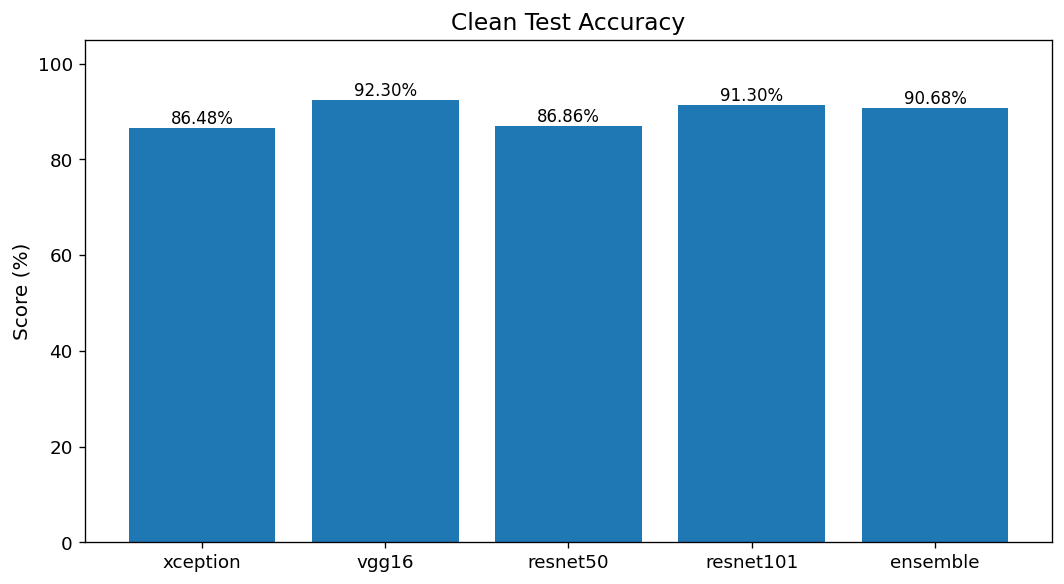

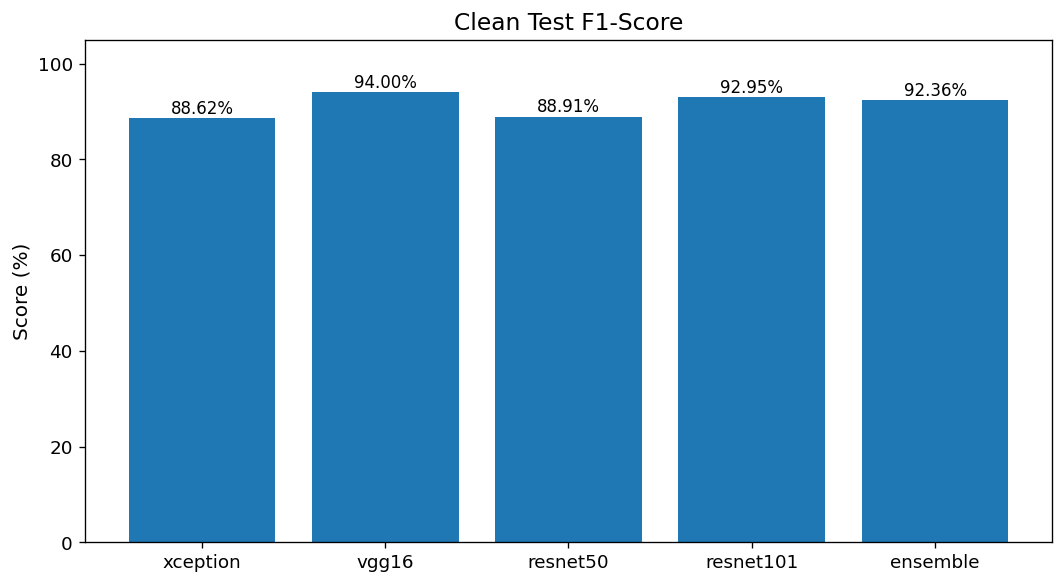

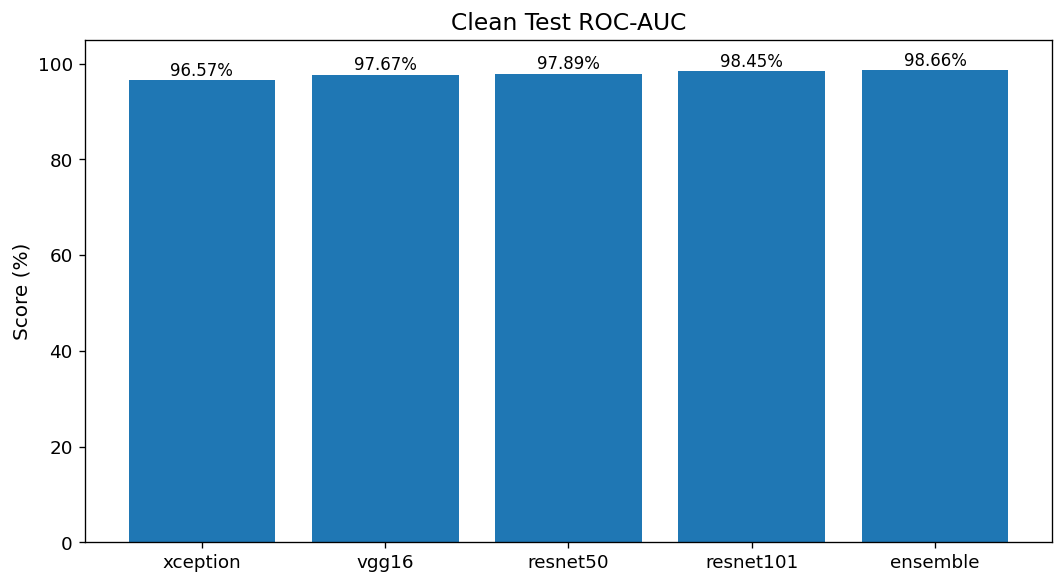

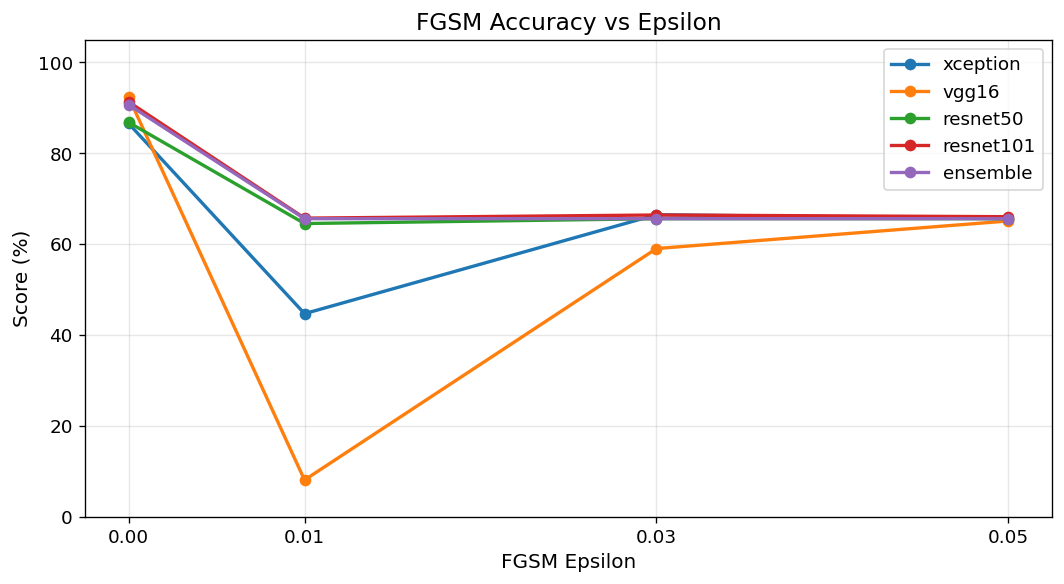

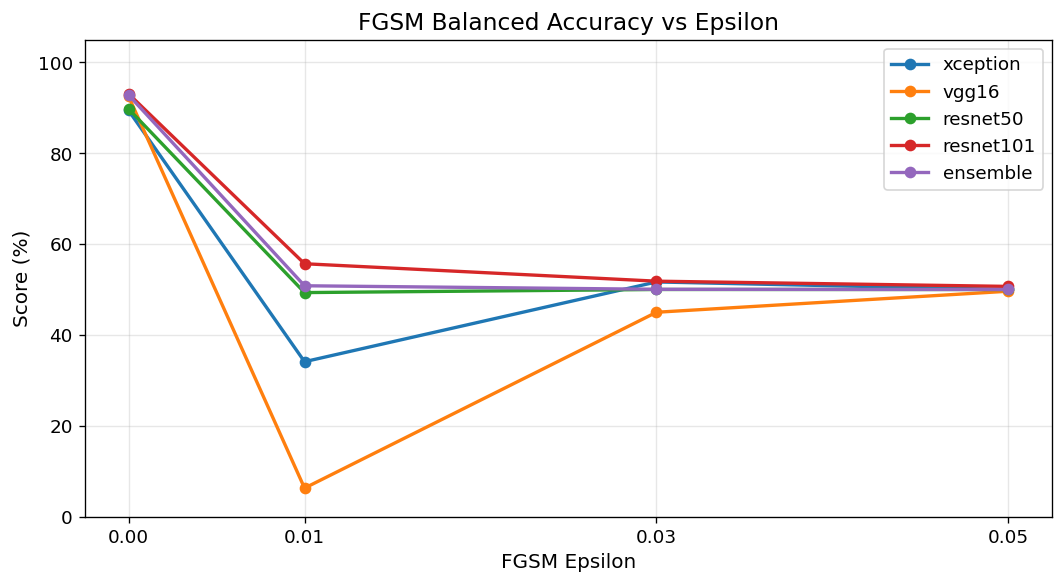

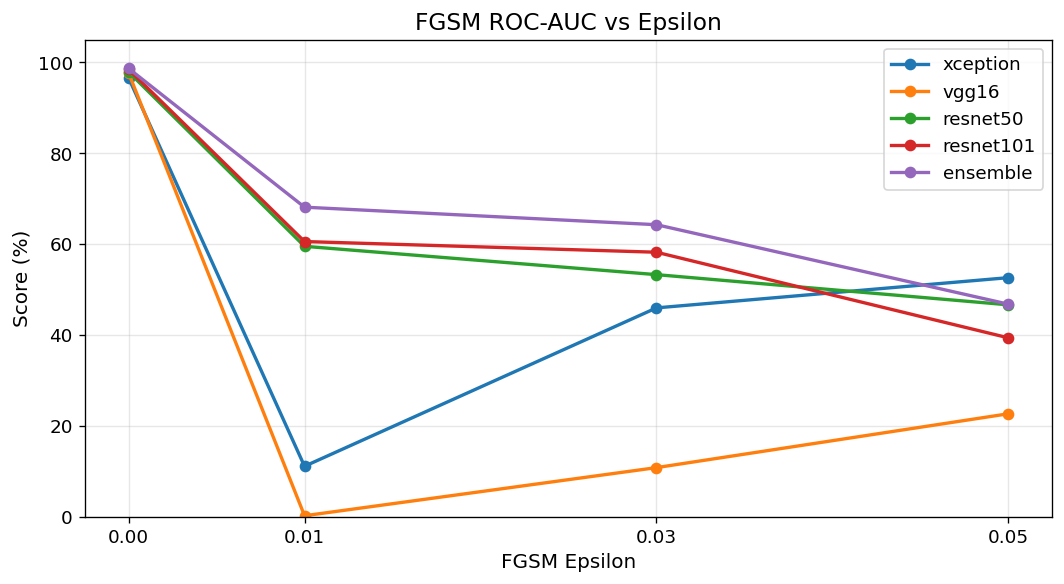

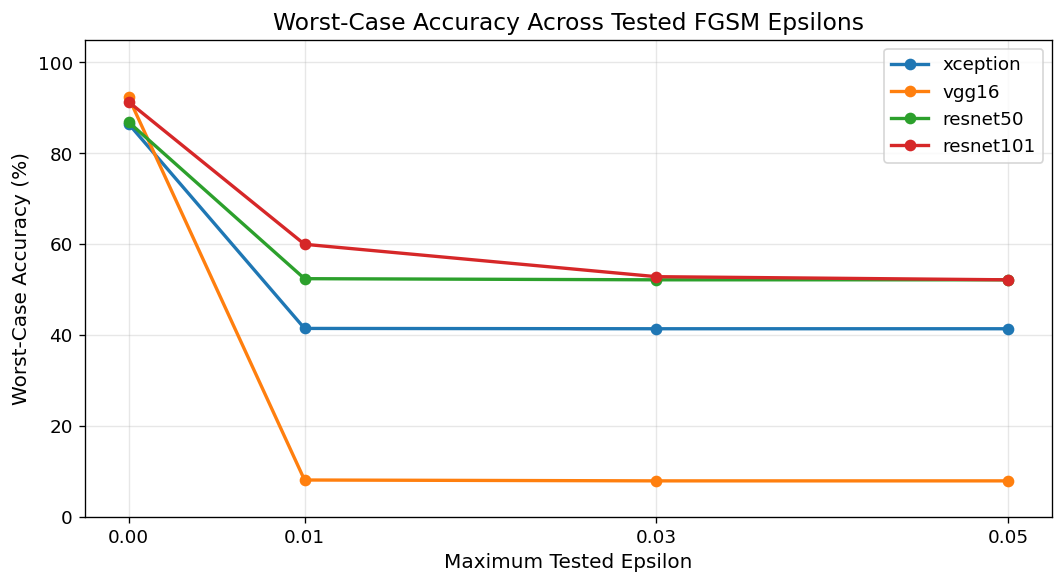

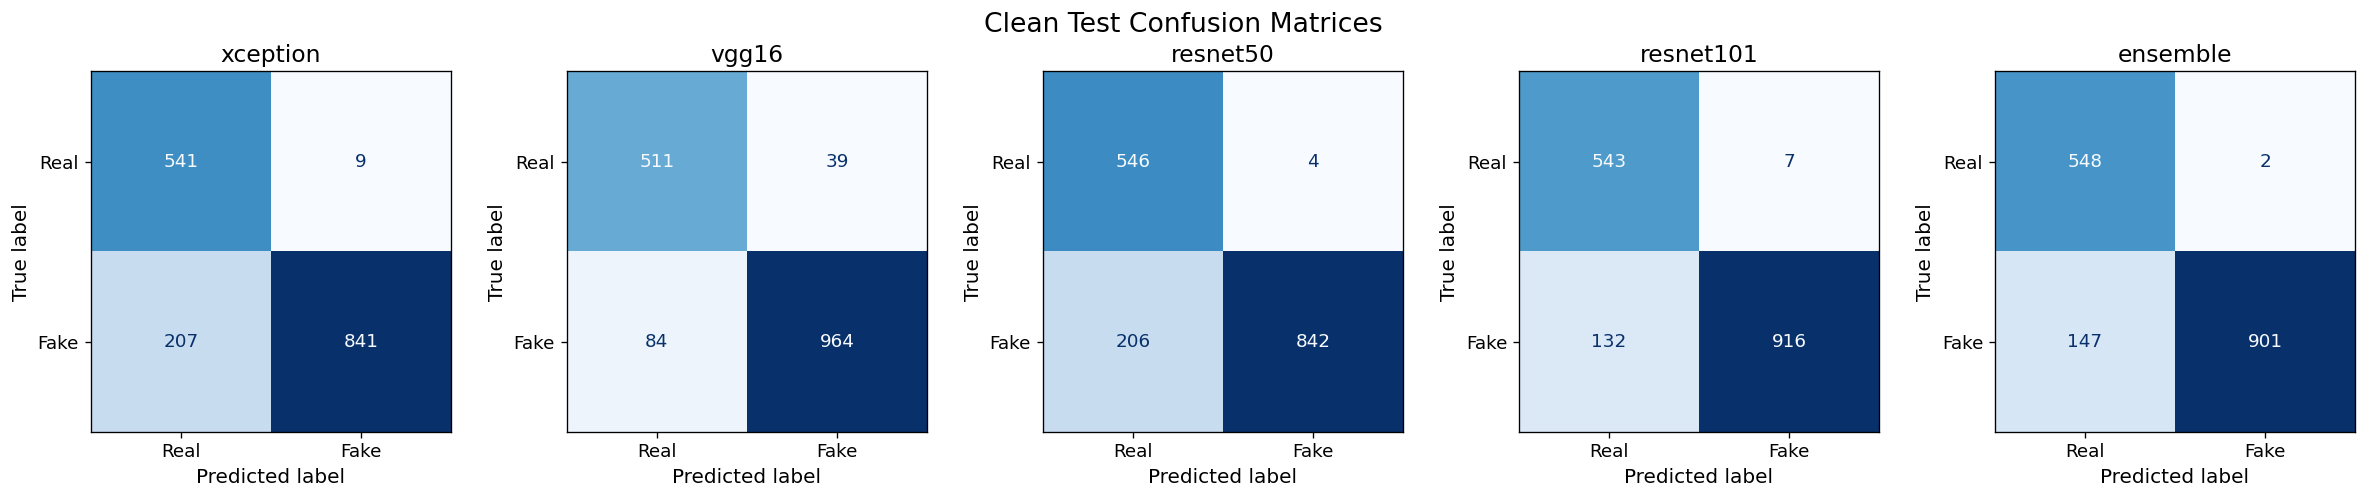


All results and figures saved to:
/kaggle/working/dfdc_reproduction/results
/kaggle/working/dfdc_reproduction/results/figures

Generated figures:
 - clean_accuracy.png
 - clean_confusion_matrices.png
 - clean_f1.png
 - clean_roc_auc.png
 - fgsm_accuracy.png
 - fgsm_balanced_accuracy.png
 - fgsm_roc_auc.png
 - fgsm_worst_case_accuracy.png


In [21]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")
RESULTS = PROJECT_DIR / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 1. Load existing results
# ------------------------------------------------

clean = pd.read_csv(RESULTS / "clean_test_results.csv")
ensemble_clean = pd.read_csv(
    RESULTS / "ensemble_clean_test_results.csv"
)

fgsm = pd.read_csv(RESULTS / "fgsm_test_results.csv")
ensemble_fgsm = pd.read_csv(
    RESULTS / "ensemble_fgsm_test_results.csv"
)

validation = pd.read_csv(
    RESULTS / "fgsm_validation_summary.csv"
)

# ------------------------------------------------
# 2. Combine clean results
# ------------------------------------------------

ensemble_clean["model"] = "ensemble"

clean_all = pd.concat(
    [clean, ensemble_clean],
    ignore_index=True
)

model_order = [
    "xception", "vgg16",
    "resnet50", "resnet101", "ensemble"
]

clean_all["model"] = pd.Categorical(
    clean_all["model"],
    categories=model_order,
    ordered=True
)

clean_all = clean_all.sort_values("model")

clean_all.to_csv(
    RESULTS / "final_clean_comparison.csv",
    index=False
)

print("FINAL CLEAN COMPARISON")
display(
    clean_all[
        ["model", "accuracy", "precision",
         "recall", "f1", "roc_auc"]
    ]
)

# ------------------------------------------------
# 3. Combine FGSM results
# ------------------------------------------------

ensemble_fgsm["model"] = "ensemble"

fgsm_all = pd.concat(
    [fgsm, ensemble_fgsm],
    ignore_index=True
)

fgsm_all["model"] = pd.Categorical(
    fgsm_all["model"],
    categories=model_order,
    ordered=True
)

fgsm_all = fgsm_all.sort_values(
    ["model", "epsilon"]
)

# Calculate balanced accuracy from confusion matrix
def parse_cm(value):
    if isinstance(value, str):
        return np.asarray(ast.literal_eval(value))
    return np.asarray(value)

def balanced_accuracy_from_cm(cm):
    tn, fp = cm[0]
    fn, tp = cm[1]

    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)

    return (specificity + sensitivity) / 2

fgsm_all["balanced_accuracy"] = (
    fgsm_all["confusion_matrix"]
    .apply(parse_cm)
    .apply(balanced_accuracy_from_cm)
)

fgsm_all.to_csv(
    RESULTS / "final_fgsm_comparison.csv",
    index=False
)

print("\nFINAL FGSM COMPARISON")
display(
    fgsm_all[
        ["model", "epsilon", "accuracy",
         "balanced_accuracy", "f1", "roc_auc"]
    ]
)

# ------------------------------------------------
# 4. Plot styling
# ------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# ------------------------------------------------
# 5. Clean accuracy, F1 and ROC-AUC
# ------------------------------------------------

for metric, title in [
    ("accuracy", "Clean Test Accuracy"),
    ("f1", "Clean Test F1-Score"),
    ("roc_auc", "Clean Test ROC-AUC")
]:

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(
        clean_all["model"].astype(str),
        clean_all[metric] * 100
    )

    ax.set_title(title)
    ax.set_ylabel("Score (%)")
    ax.set_ylim(0, 105)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 1,
            f"{bar.get_height():.2f}%",
            ha="center",
            fontsize=10
        )

    save_plot(f"clean_{metric}.png")

# ------------------------------------------------
# 6. FGSM accuracy and balanced accuracy
# ------------------------------------------------

for metric, title, filename in [
    (
        "accuracy",
        "FGSM Accuracy vs Epsilon",
        "fgsm_accuracy.png"
    ),
    (
        "balanced_accuracy",
        "FGSM Balanced Accuracy vs Epsilon",
        "fgsm_balanced_accuracy.png"
    ),
    (
        "roc_auc",
        "FGSM ROC-AUC vs Epsilon",
        "fgsm_roc_auc.png"
    )
]:

    fig, ax = plt.subplots(figsize=(9, 5))

    for model_name in model_order:

        subset = fgsm_all[
            fgsm_all["model"] == model_name
        ].sort_values("epsilon")

        ax.plot(
            subset["epsilon"],
            subset[metric] * 100,
            marker="o",
            linewidth=2,
            label=model_name
        )

    ax.set_title(title)
    ax.set_xlabel("FGSM Epsilon")
    ax.set_ylabel("Score (%)")
    ax.set_xticks([0.00, 0.01, 0.03, 0.05])
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3)
    ax.legend()

    save_plot(filename)

# ------------------------------------------------
# 7. Worst-case FGSM accuracy
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

for model_name in model_order[:-1]:

    subset = validation[
        validation["model"] == model_name
    ].sort_values("epsilon")

    ax.plot(
        subset["epsilon"],
        subset["worst_case_accuracy_%"],
        marker="o",
        linewidth=2,
        label=model_name
    )

ax.set_title(
    "Worst-Case Accuracy Across Tested FGSM Epsilons"
)
ax.set_xlabel("Maximum Tested Epsilon")
ax.set_ylabel("Worst-Case Accuracy (%)")
ax.set_xticks([0.00, 0.01, 0.03, 0.05])
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()

save_plot("fgsm_worst_case_accuracy.png")

# ------------------------------------------------
# 8. Clean confusion matrices
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 5, figsize=(20, 4)
)

for ax, (_, row) in zip(
    axes, clean_all.iterrows()
):

    cm = parse_cm(row["confusion_matrix"])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Real", "Fake"]
    ).plot(
        ax=ax,
        colorbar=False,
        cmap="Blues",
        values_format="d"
    )

    ax.set_title(str(row["model"]))

fig.suptitle(
    "Clean Test Confusion Matrices",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    FIGURES / "clean_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nAll results and figures saved to:")
print(RESULTS)
print(FIGURES)

print("\nGenerated figures:")
for file in sorted(FIGURES.glob("*.png")):
    print(" -", file.name)

In [22]:
from pathlib import Path
import shutil

source = Path("/kaggle/working/dfdc_reproduction")
backup = Path("/kaggle/working/dfdc_permanent_backup")

backup.mkdir(parents=True, exist_ok=True)

# Copy project files, excluding unnecessary caches
shutil.copytree(
    source,
    backup,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns(
        "__pycache__", "*.pyc", ".ipynb_checkpoints"
    )
)

print("Backup prepared at:", backup)

checkpoints = sorted(backup.rglob("*_best.pth"))
print("\nBest model checkpoints:", len(checkpoints))

for file in checkpoints:
    print(file.relative_to(backup),
          round(file.stat().st_size / 1024**2, 2), "MB")

print("\nResults files:", len(list((backup / "results").rglob("*"))))

Backup prepared at: /kaggle/working/dfdc_permanent_backup

Best model checkpoints: 4
checkpoints/resnet101_best.pth 288.96 MB
checkpoints/resnet50_best.pth 216.21 MB
checkpoints/vgg16_best.pth 113.18 MB
checkpoints/xception_best.pth 143.5 MB

Results files: 25


In [23]:
import kagglehub

handle = "haiderrasoolqadri/dfdc-trained-models-results"

kagglehub.dataset_upload(
    handle,
    "/kaggle/working/dfdc_permanent_backup"
)

print("Dataset upload request completed!")
print("https://www.kaggle.com/datasets/" + handle)

Uploading Dataset https://kaggle.com/datasets/haiderrasoolqadri/dfdc-trained-models-results ...
Starting upload for file /kaggle/working/dfdc_permanent_backup/evaluate.py
Starting upload for file /kaggle/working/dfdc_permanent_backup/dataset.py
Starting upload for file /kaggle/working/dfdc_permanent_backup/dfdc_split_manifest.csv
Starting upload for file /kaggle/working/dfdc_permanent_backup/ensemble.py
Starting upload for file /kaggle/working/dfdc_permanent_backup/trainer.py
Starting upload for file /kaggle/working/dfdc_permanent_backup/config.py
Starting upload for file /kaggle/working/dfdc_permanent_backup/checkpoints/vgg16_best.pth
Starting upload for file /kaggle/working/dfdc_permanent_backup/checkpoints/xception_latest.pth


Uploading:   0%|          | 0.00/150M [00:00<?, ?B/s]
Uploading:   0%|          | 0.00/1.90k [00:00<?, ?B/s]

Uploading:   0%|          | 0.00/119M [00:00<?, ?B/s]



Uploading:   0%|          | 0.00/1.12M [00:00<?, ?B/s]


Uploading:   0%|          | 0.00/2.09k [00:00<?, ?B/s]





Uploading:   0%|          | 0.00/1.08k [00:00<?, ?B/s]




Uploading:   0%|          | 32.8k/150M [00:00<07:39, 327kB/s][A






Uploading:   0%|          | 0.00/287 [00:00<?, ?B/s]
Uploading: 100%|██████████| 1.90k/1.90k [00:00<00:00, 18.3kB/s]

Uploading:   0%|          | 16.4k/119M [00:00<15:51, 125kB/s]



Uploading:   5%|▍         | 7.08M/150M [00:00<00:03, 40.6MB/s]


Uploading: 100%|██████████| 2.09k/2.09k [00:00<00:00, 13.5kB/s]




Uploading: 100%|██████████| 6.34k/6.34k [00:00<00:00, 42.0kB/s]

Uploading:   6%|▌         | 7.36M/119M [00:00<00:02, 38.3MB/s]





Uploading: 100%|██████████| 1.08k/1.08k [00:00<00:00, 6.13kB/s]






Uploading: 100%|██████████| 1.90k/1.90k [00:00<00:00, 6.13kB/s][A

Upload successful: /kaggle/working/dfdc_permanent_backup/evaluate.py (2KB)
Starting upload for file /kaggle/working/dfdc_permanent_backup/checkpoints/resnet50_best.pth





Uploading: 100%|██████████| 1.12M/1.12M [00:00<00:00, 3.46MB/s][A

Upload successful: /kaggle/working/dfdc_permanent_backup/dfdc_split_manifest.csv (1MB)


Starting upload for file /kaggle/working/dfdc_permanent_backup/checkpoints/resnet50_latest.pth


... (97 outputs left out)

Upload successful: /kaggle/working/dfdc_permanent_backup/checkpoints/resnet101_best.pth (289MB)



Uploading: 100%|██████████| 303M/303M [00:10<00:00, 28.4MB/s]

Upload successful: /kaggle/working/dfdc_permanent_backup/checkpoints/resnet101_latest.pth (289MB)


Your dataset has been created.
Files are being processed...
See at: https://kaggle.com/datasets/haiderrasoolqadri/dfdc-trained-models-results
Dataset upload request completed!
https://www.kaggle.com/datasets/haiderrasoolqadri/dfdc-trained-models-results


In [16]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

def diagnose_fgsm(name):
    print(f"\nEvaluating {name.upper()}...")

    model = load_trained_model(name, DEVICE)

    batch_size = MODEL_CONFIGS[name]["batch_size"]
    test_loader = get_dataloaders(batch_size)["test"]

    y_true, clean_pred, adv_pred = [], [], []
    max_deltas, mean_deltas = [], []
    clean_losses, adv_losses = [], []

    model.eval()

    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.no_grad():
            logits = model(images)
            clean_predictions = logits.argmax(dim=1)
            clean_loss = F.cross_entropy(
                logits, labels, reduction="none"
            )

        adversarial = fgsm_attack(
            model, images, labels, epsilon=0.01
        )

        with torch.no_grad():
            adv_logits = model(adversarial)
            adv_predictions = adv_logits.argmax(dim=1)
            adv_loss = F.cross_entropy(
                adv_logits, labels, reduction="none"
            )

        delta = (adversarial - images).abs()

        max_deltas.extend(
            delta.flatten(1).max(dim=1).values.cpu().tolist()
        )
        mean_deltas.extend(
            delta.flatten(1).mean(dim=1).cpu().tolist()
        )

        clean_losses.extend(clean_loss.cpu().tolist())
        adv_losses.extend(adv_loss.cpu().tolist())

        y_true.extend(labels.cpu().tolist())
        clean_pred.extend(clean_predictions.cpu().tolist())
        adv_pred.extend(adv_predictions.cpu().tolist())

    y = np.array(y_true)
    clean = np.array(clean_pred)
    adv = np.array(adv_pred)

    real = y == 0
    fake = y == 1

    result = {
        "model": name,
        "epsilon": 0.01,
        "n_samples": len(y),
        "n_real": int(real.sum()),
        "n_fake": int(fake.sum()),
        "clean_accuracy": (clean == y).mean(),
        "fgsm_accuracy": (adv == y).mean(),
        "fgsm_real_recall": (adv[real] == 0).mean(),
        "fgsm_fake_recall": (adv[fake] == 1).mean(),
        "fgsm_balanced_accuracy": (
            (adv[real] == 0).mean() +
            (adv[fake] == 1).mean()
        ) / 2,
        "predicted_real": int((adv == 0).sum()),
        "predicted_fake": int((adv == 1).sum()),
        "correct_to_wrong": int(
            ((clean == y) & (adv != y)).sum()
        ),
        "wrong_to_correct": int(
            ((clean != y) & (adv == y)).sum()
        ),
        "max_perturbation": max(max_deltas),
        "mean_perturbation": np.mean(mean_deltas),
        "clean_loss": np.mean(clean_losses),
        "fgsm_loss": np.mean(adv_losses),
    }

    pd.DataFrame({
        "true_label": y,
        "clean_prediction": clean,
        "fgsm_prediction": adv
    }).to_csv(
        OUTPUT_DIR / f"{name}_eps001_predictions.csv",
        index=False
    )

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return result

print("Diagnostic function ready!")


Diagnostic function ready!


In [17]:

results = []

for name in MODELS:
    result = diagnose_fgsm(name)
    results.append(result)

diagnostic_df = pd.DataFrame(results)

diagnostic_df.to_csv(
    OUTPUT_DIR / "fgsm_eps001_diagnostic_summary.csv",
    index=False
)

display(diagnostic_df.round(4))

print("\nDiagnostic completed!")
print("Saved at:", OUTPUT_DIR)



Evaluating XCEPTION...


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(



Evaluating VGG16...

Evaluating RESNET50...

Evaluating RESNET101...


,model,epsilon,n_samples,n_real,n_fake,clean_accuracy,fgsm_accuracy,fgsm_real_recall,fgsm_fake_recall,fgsm_balanced_accuracy,predicted_real,predicted_fake,correct_to_wrong,wrong_to_correct,max_perturbation,mean_perturbation,clean_loss,fgsm_loss
0,xception,0.01,1598,550,1048,0.8655,0.4468,0.0018,0.6803,0.3411,336,1262,722,53,0.01,0.01,0.4301,3.4312
1,vgg16,0.01,1598,550,1048,0.9237,0.0807,0.0055,0.1202,0.0628,925,673,1347,0,0.01,0.01,0.1964,7.6335
2,resnet50,0.01,1598,550,1048,0.8680,0.6458,0.0073,0.9809,0.4941,24,1574,551,196,0.01,0.01,0.4015,2.7559
3,resnet101,0.01,1598,550,1048,0.9130,0.6571,0.2345,0.8788,0.5567,256,1342,499,90,0.01,0.01,0.2505,0.8749



Diagnostic completed!
Saved at: /kaggle/working/dfdc_reproduction/results/fgsm_diagnostics


In [7]:

from pathlib import Path
import shutil
import sys
import importlib

OLD_DATASET = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/dfdc-trained-models-results"
)
PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")

if not OLD_DATASET.is_dir():
    raise FileNotFoundError("Existing dataset not mounted.")

shutil.copytree(
    OLD_DATASET,
    PROJECT_DIR,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns(
        "*.tex", "__pycache__", ".ipynb_checkpoints"
    )
)

# Make project imports available
sys.path.insert(0, str(PROJECT_DIR))
sys.path_importer_cache.pop(str(PROJECT_DIR), None)
importlib.invalidate_caches()

import config
import torch

print("Project restored:", PROJECT_DIR.exists())
print("Dataset available:", config.DATA_ROOT.exists())
print("GPU available:", torch.cuda.is_available())

for name in ["xception", "vgg16", "resnet50", "resnet101"]:
    checkpoint = PROJECT_DIR / "checkpoints" / f"{name}_best.pth"
    print(name, "FOUND" if checkpoint.exists() else "MISSING")


Project restored: True
Dataset available: True
GPU available: True
xception FOUND
vgg16 FOUND
resnet50 FOUND
resnet101 FOUND


In [5]:

from pathlib import Path
import shutil
import sys
import importlib

OLD_DATASET = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/dfdc-trained-models-results"
)
PROJECT_DIR = Path("/kaggle/working/dfdc_reproduction")

if not OLD_DATASET.is_dir():
    raise FileNotFoundError("Existing dataset not mounted.")

shutil.copytree(
    OLD_DATASET,
    PROJECT_DIR,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns(
        "*.tex", "__pycache__", ".ipynb_checkpoints"
    )
)

# Make project imports available
sys.path.insert(0, str(PROJECT_DIR))
sys.path_importer_cache.pop(str(PROJECT_DIR), None)
importlib.invalidate_caches()

import config
import torch

print("Project restored:", PROJECT_DIR.exists())
print("Dataset available:", config.DATA_ROOT.exists())
print("GPU available:", torch.cuda.is_available())

for name in ["xception", "vgg16", "resnet50", "resnet101"]:
    checkpoint = PROJECT_DIR / "checkpoints" / f"{name}_best.pth"
    print(name, "FOUND" if checkpoint.exists() else "MISSING")


Project restored: True
Dataset available: True
GPU available: True
xception FOUND
vgg16 FOUND
resnet50 FOUND
resnet101 FOUND


In [6]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from config import MODEL_CONFIGS, RESULTS_DIR
from dataset import get_dataloaders
from evaluate import load_trained_model
from attacks.fgsm import fgsm_attack

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODELS = ["xception", "vgg16", "resnet50", "resnet101"]
OUTPUT_DIR = RESULTS_DIR / "fgsm_diagnostics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def diagnose_fgsm(name):
    print(f"\nEvaluating {name.upper()}...")

    model = load_trained_model(name, DEVICE)
    loader = get_dataloaders(
        MODEL_CONFIGS[name]["batch_size"]
    )["test"]

    y_true, clean_pred, adv_pred = [], [], []
    max_deltas, mean_deltas = [], []
    clean_losses, adv_losses = [], []

    model.eval()

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.no_grad():
            logits = model(images)
            clean_predictions = logits.argmax(1)
            clean_loss = F.cross_entropy(
                logits, labels, reduction="none"
            )

        adversarial = fgsm_attack(
            model, images, labels, epsilon=0.01
        )

        with torch.no_grad():
            adv_logits = model(adversarial)
            adv_predictions = adv_logits.argmax(1)
            adv_loss = F.cross_entropy(
                adv_logits, labels, reduction="none"
            )

        delta = (adversarial - images).abs()

        max_deltas.extend(
            delta.flatten(1).max(1).values.cpu().tolist()
        )
        mean_deltas.extend(
            delta.flatten(1).mean(1).cpu().tolist()
        )

        clean_losses.extend(clean_loss.cpu().tolist())
        adv_losses.extend(adv_loss.cpu().tolist())

        y_true.extend(labels.cpu().tolist())
        clean_pred.extend(clean_predictions.cpu().tolist())
        adv_pred.extend(adv_predictions.cpu().tolist())

    y = np.array(y_true)
    clean = np.array(clean_pred)
    adv = np.array(adv_pred)

    real = y == 0
    fake = y == 1

    real_recall = (adv[real] == 0).mean()
    fake_recall = (adv[fake] == 1).mean()

    result = {
        "model": name,
        "epsilon": 0.01,
        "n_samples": len(y),
        "n_real": int(real.sum()),
        "n_fake": int(fake.sum()),
        "clean_accuracy": (clean == y).mean(),
        "fgsm_accuracy": (adv == y).mean(),
        "fgsm_real_recall": real_recall,
        "fgsm_fake_recall": fake_recall,
        "fgsm_balanced_accuracy":
            (real_recall + fake_recall) / 2,
        "predicted_real": int((adv == 0).sum()),
        "predicted_fake": int((adv == 1).sum()),
        "correct_to_wrong":
            int(((clean == y) & (adv != y)).sum()),
        "wrong_to_correct":
            int(((clean != y) & (adv == y)).sum()),
        "max_perturbation": max(max_deltas),
        "mean_perturbation": np.mean(mean_deltas),
        "clean_loss": np.mean(clean_losses),
        "fgsm_loss": np.mean(adv_losses),
    }

    pd.DataFrame({
        "true_label": y,
        "clean_prediction": clean,
        "fgsm_prediction": adv
    }).to_csv(
        OUTPUT_DIR / f"{name}_eps001_predictions.csv",
        index=False
    )

    del model

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return result


results = []

for name in MODELS:
    results.append(diagnose_fgsm(name))

diagnostic_df = pd.DataFrame(results)

diagnostic_df.to_csv(
    OUTPUT_DIR / "fgsm_eps001_diagnostic_summary.csv",
    index=False
)

display(diagnostic_df.round(4))

print("\nDiagnostics saved:", OUTPUT_DIR)



Evaluating XCEPTION...


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(



Evaluating VGG16...

Evaluating RESNET50...

Evaluating RESNET101...


,model,epsilon,n_samples,n_real,n_fake,clean_accuracy,fgsm_accuracy,fgsm_real_recall,fgsm_fake_recall,fgsm_balanced_accuracy,predicted_real,predicted_fake,correct_to_wrong,wrong_to_correct,max_perturbation,mean_perturbation,clean_loss,fgsm_loss
0,xception,0.01,1598,550,1048,0.8655,0.4468,0.0018,0.6803,0.3411,336,1262,722,53,0.01,0.01,0.4301,3.4311
1,vgg16,0.01,1598,550,1048,0.9237,0.0807,0.0055,0.1202,0.0628,925,673,1347,0,0.01,0.01,0.1964,7.6335
2,resnet50,0.01,1598,550,1048,0.8680,0.6458,0.0073,0.9809,0.4941,24,1574,551,196,0.01,0.01,0.4015,2.7558
3,resnet101,0.01,1598,550,1048,0.9130,0.6571,0.2345,0.8788,0.5567,256,1342,499,90,0.01,0.01,0.2505,0.8749



Diagnostics saved: /kaggle/working/dfdc_reproduction/results/fgsm_diagnostics


In [8]:

from pathlib import Path
import json
import shutil
import subprocess
import pandas as pd

DATASET_ID = "haiderrasoolqadri/dfdc-trained-models-results"

PROJECT = Path("/kaggle/working/dfdc_reproduction")
EXPORT = Path("/kaggle/working/dfdc_dataset_update")
DIAG = PROJECT / "results/fgsm_diagnostics"

# 1. Verify new diagnostic files
required_diagnostics = [
    "fgsm_eps001_diagnostic_summary.csv",
    "xception_eps001_predictions.csv",
    "vgg16_eps001_predictions.csv",
    "resnet50_eps001_predictions.csv",
    "resnet101_eps001_predictions.csv",
]

for filename in required_diagnostics:
    assert (DIAG / filename).is_file(), f"Missing: {filename}"

summary = pd.read_csv(
    DIAG / "fgsm_eps001_diagnostic_summary.csv"
)

assert len(summary) == 4
assert (summary["n_samples"] == 1598).all()
assert (summary["epsilon"] == 0.01).all()
assert (summary["max_perturbation"] <= 0.010001).all()

# 2. Prepare export folder
if EXPORT.exists():
    shutil.rmtree(EXPORT)

shutil.copytree(
    PROJECT,
    EXPORT,
    ignore=shutil.ignore_patterns(
        "*.tex",
        "__pycache__",
        ".ipynb_checkpoints",
        "*.pyc"
    )
)

# 3. Preserve existing dataset metadata when available
old_metadata = Path(
    "/kaggle/input/datasets/haiderrasoolqadri/"
    "dfdc-trained-models-results/dataset-metadata.json"
)

if old_metadata.exists():
    metadata = json.loads(old_metadata.read_text())
else:
    metadata = {
        "title": "DFDC Trained Models and Results",
        "licenses": [{"name": "unknown"}]
    }

metadata["id"] = DATASET_ID

(EXPORT / "dataset-metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

# 4. Verify essential files
required = [
    "config.py",
    "dataset.py",
    "checkpoints/xception_best.pth",
    "checkpoints/vgg16_best.pth",
    "checkpoints/resnet50_best.pth",
    "checkpoints/resnet101_best.pth",
    "results/clean_test_results.csv",
    "results/fgsm_test_results.csv",
    "results/fgsm_diagnostics/fgsm_eps001_diagnostic_summary.csv",
]

for filename in required:
    assert (EXPORT / filename).is_file(), f"Missing: {filename}"

assert not list(EXPORT.rglob("*.tex")), "Unexpected LaTeX file!"

files = [p for p in EXPORT.rglob("*") if p.is_file()]
size_gb = sum(p.stat().st_size for p in files) / 1024**3

print("Files ready:", len(files))
print("Total size (GB):", round(size_gb, 3))
print("Diagnostics verified.")
print("No .tex files included.")

# 5. Publish new version of EXISTING dataset
cmd = [
    "kaggle", "datasets", "version",
    "-p", str(EXPORT),
    "-m", "Added final FGSM epsilon 0.01 diagnostic results",
    "--dir-mode", "zip"
]

print("\nUploading new dataset version...")

result = subprocess.run(cmd, text=True, capture_output=True)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset version upload failed.")

print("\nDataset version uploaded successfully!")
print("https://www.kaggle.com/datasets/" + DATASET_ID)


Files ready: 51
Total size (GB): 1.49
Diagnostics verified.
No .tex files included.

Uploading new dataset version...
Starting upload for file trainer.py
Upload successful: trainer.py (6KB)
Starting upload for file dataset.py
Upload successful: dataset.py (2KB)
Starting upload for file evaluate.py
Upload successful: evaluate.py (2KB)
Starting upload for file results.zip
Upload successful: results.zip (1MB)
Starting upload for file checkpoints.zip
Upload successful: checkpoints.zip (1GB)
Starting upload for file models.zip
Upload successful: models.zip (2KB)
Starting upload for file config.py
Upload successful: config.py (1KB)
Starting upload for file ensemble.py
Upload successful: ensemble.py (287B)
Starting upload for file dfdc_split_manifest.csv
Upload successful: dfdc_split_manifest.csv (1MB)
Starting upload for file attacks.zip
Upload successful: attacks.zip (642B)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/haiderrasoolqadri/dfdc-trai